# Notebook 03 — การฝึก YOLO สถาปัตยกรรม และการวัดประสิทธิภาพ

**วัตถุประสงค์** สร้าง baseline ที่ทำซ้ำได้ ศึกษาโครงสร้างภายในของแบบจำลองจาก activation จริง วัดต้นทุนการคำนวณรายชั้นและทั้งแบบจำลอง เปรียบเทียบ AdamW กับ MuSGD ทดลอง attention module ทดลอง quantization และประเมินผลบน test ครั้งเดียวหลังตรึงการตั้งค่า (RQ4–RQ8, RQ10, RQ11)

**ลำดับและด่านตรวจ**

1. ตรวจเวอร์ชัน โครงสร้าง และ module ของ YOLO26n-seg ที่ติดตั้งจริง
2. Baseline = สูตรที่เลือกจาก Notebook 02 (`configs/aug_recipe_selected.json`) และตรวจการทำซ้ำได้
3. Feature map และต้นทุนรายชั้น (ไม่ต้องฝึกเพิ่ม)
4. ทดลอง optimizer และ attention (เลือกด้วย val เท่านั้น)
5. ยืนยันด้วย grouped CV 3 fold → ตรึงการตั้งค่า (G4)
6. ประเมินบน test **ครั้งเดียว** → quantization และสรุป

| ส่วน | ประเภท | เวลาโดยประมาณ |
|---|---|---|
| 1, 3 โครงสร้าง, feature map, benchmark รายชั้น | GPU สั้น | 10–15 นาที |
| 2 การทดสอบการทำซ้ำได้ (2 × 3 epoch) | **GPU [EXPENSIVE]** | ~5 นาที |
| 5 MuSGD 3 seed | **GPU [EXPENSIVE]** | ~40 นาที |
| 6 attention 4 arm × 2 seed | **GPU [EXPENSIVE]** | ~1.7 ชั่วโมง |
| 7 grouped CV 3 fold × 2 การตั้งค่า | **GPU [EXPENSIVE]** | ~1.2 ชั่วโมง |
| 10 quantization และ benchmark | GPU/CPU | ~1 ชั่วโมง |

## 0. การตั้งค่า

In [1]:
import os, sys, re, json, time, hashlib, platform, subprocess, random, math, shutil, gzip, warnings, contextlib, io
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon

warnings.filterwarnings("ignore", category=RuntimeWarning)
# sklearn เตือนเมื่อสถานะที่ทำนายไม่มีในป้ายจริง หรือ bootstrap ได้สถานะเดียว ค่า metric ยังถูกต้องตามนิยาม จึงปิดเพื่อให้ output อ่านง่าย
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
warnings.filterwarnings("ignore", message="A single label was found")
warnings.filterwarnings("ignore", message=".*should not be empty.*")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
assert (ROOT / "RESEARCH_PLAN.md").exists(), f"ROOT ไม่ถูกต้อง: {ROOT}"
CLASS_NAMES = ["gravel", "sand"]
CLASS_COLORS = {"gravel": "#0072B2", "sand": "#E69F00", "mixed": "#999999", "none": "#DDDDDD"}
STATES = ["none", "gravel", "sand", "mixed"]

# ชุดข้อมูลพัฒนาล่าสุดที่ Notebook 01 บันทึกไว้
VERSIONS = json.loads((ROOT / "manifests" / "dataset_versions.json").read_text())
DEV = VERSIONS[-1]
DEV_DIR = ROOT / "data" / f"dev_{DEV['dev_hash']}"
SILVER_DIR = ROOT / "data" / f"silver_{DEV['silver_hash']}"
MANIFEST = pd.read_csv(ROOT / DEV["manifest"])
assert (DEV_DIR / "data.yaml").exists() and (DEV_DIR / "split_meta.json").exists(), "ต้องรัน Notebook 01 ก่อน"
SPLIT_META = json.loads((DEV_DIR / "split_meta.json").read_text())

NOTEBOOK = "03_yolo_training_architecture_and_benchmarking"
OUT_ROOT = ROOT / "outputs" / "03_yolo_experiments"
OUT_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "grid.linewidth": 0.5})

def cfg_hash(d, n=10):
    return hashlib.sha256(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:n]

def sha256_file(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def savefig(fig, path_no_ext):
    path_no_ext = Path(path_no_ext); path_no_ext.parent.mkdir(parents=True, exist_ok=True)
    for ext in ("png", "pdf"):
        fig.savefig(f"{path_no_ext}.{ext}", bbox_inches="tight")
    print(f"saved figure: {path_no_ext.relative_to(ROOT)}.png|pdf")

def save_table(df, path, index=False):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=index)
    print(f"saved table: {path.relative_to(ROOT)} ({len(df)} rows)")

def split_images(split):
    # คืนรายการภาพของ split พร้อม path ในชุดพัฒนา
    m = MANIFEST[MANIFEST.split == split].copy()
    m["path"] = [str(DEV_DIR / split / "images" / n) for n in m.silver_name]
    m["label_path"] = [str(DEV_DIR / split / "labels" / (Path(n).stem + ".txt")) for n in m.silver_name]
    return m.reset_index(drop=True)

def guard_not_test(paths, allow=False):
    # ป้องกันการโหลดภาพ test ก่อนขั้นประเมินสุดท้าย
    test_dir = str(DEV_DIR / "test")
    bad = [p for p in paths if str(p).startswith(test_dir)]
    if bad and not allow:
        raise PermissionError(f"{len(bad)} test images requested outside the final-evaluation cell")

print("ROOT:", ROOT); print("DEV :", DEV_DIR.relative_to(ROOT), "| silver:", SILVER_DIR.relative_to(ROOT))
print("splits:", SPLIT_META["counts"])

RUN_TRAINING = True         # [EXPENSIVE] เปิดเพื่อฝึกในหัวข้อ 2, 5, 6, 7
RUN_TEST_EVAL = True        # เปิดได้ครั้งเดียวหลังผ่านด่าน G4 (หัวข้อ 8)
RUN_EXPORT = False          # quantization และ benchmark ของ format ที่ export (หัวข้อ 10)
SUB = {k: OUT_ROOT / k for k in ["baseline", "optimizer_comparison", "architecture_ablations", "quantization",
                                 "feature_maps", "layer_benchmarks", "evaluation", "cv"]}
for d in SUB.values():
    d.mkdir(parents=True, exist_ok=True)
FIG = OUT_ROOT / "figures"; TAB = OUT_ROOT / "tables"; FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
TRAIN = split_images("train"); VAL = split_images("val")
guard_not_test(TRAIN.path); guard_not_test(VAL.path)
SEL = json.loads((ROOT / "configs" / "aug_recipe_selected.json").read_text()) if (ROOT / "configs" / "aug_recipe_selected.json").exists() else None
print("selected recipe from Notebook 02:", None if SEL is None else SEL["arm"])

ROOT: /home/supawich/Desktop/Aggregate_Project/implement/research
DEV : data/dev_19659e679798 | silver: data/silver_0997f3096843
splits: {'train': 714, 'val': 131, 'test': 244}
selected recipe from Notebook 02: A9_selected


In [2]:
def pkg_version(name):
    try:
        from importlib.metadata import version
        return version(name)
    except Exception:
        return None

def environment_record():
    rec = dict(timestamp=time.strftime("%Y-%m-%dT%H:%M:%S%z"), python=sys.version.split()[0], platform=platform.platform(),
               cpu=platform.processor(), cpu_count=os.cpu_count(),
               packages={p: pkg_version(p) for p in ["torch", "torchvision", "ultralytics", "numpy", "opencv-python",
                                                     "albumentations", "pycocotools", "onnx", "onnxruntime", "openvino",
                                                     "tensorrt", "nncf", "ncnn", "sahi", "scikit-learn", "scikit-image", "thop",
                                                     "ultralytics-thop"]})
    try:
        import torch
        rec["cuda_available"] = torch.cuda.is_available()
        rec["torch_cuda"] = torch.version.cuda
        rec["cudnn"] = torch.backends.cudnn.version()
        if torch.cuda.is_available():
            p = torch.cuda.get_device_properties(0)
            rec["gpu"] = dict(name=p.name, total_memory_gb=round(p.total_memory / 2**30, 2), capability=f"{p.major}.{p.minor}")
    except Exception as e:
        rec["torch_error"] = str(e)
    try:
        rec["nvidia_smi"] = subprocess.check_output(["nvidia-smi", "--query-gpu=name,driver_version,memory.total",
                                                     "--format=csv,noheader"], text=True).strip()
    except Exception:
        rec["nvidia_smi"] = None
    try:
        rec["git_commit"] = subprocess.check_output(["git", "-C", str(ROOT), "rev-parse", "HEAD"], text=True).strip()
    except Exception:
        rec["git_commit"] = None
    return rec

ENV = environment_record()
(OUT_ROOT / "env_manifest.json").write_text(json.dumps(ENV, indent=2))
print(json.dumps(ENV, indent=2))

{
  "timestamp": "2026-10-18T17:26:54+0700",
  "python": "3.12.3",
  "platform": "Linux-7.0.0-38-generic-x86_64-with-glibc2.39",
  "cpu": "x86_64",
  "cpu_count": 20,
  "packages": {
    "torch": "2.14.1",
    "torchvision": "0.29.1",
    "ultralytics": "8.4.180",
    "numpy": "2.5.4",
    "opencv-python": "5.0.0.93",
    "albumentations": "2.0.8",
    "pycocotools": "2.0.11",
    "onnx": "1.23.2",
    "onnxruntime": "1.31.0",
    "openvino": "2026.4.1",
    "tensorrt": null,
    "nncf": null,
    "ncnn": null,
    "sahi": "0.12.8",
    "scikit-learn": "1.9.1",
    "scikit-image": "0.26.0",
    "thop": null,
    "ultralytics-thop": "2.2.2"
  },
  "cuda_available": true,
  "torch_cuda": "13.0",
  "cudnn": 92400,
  "gpu": {
    "name": "NVIDIA GeForce RTX 3080 Ti",
    "total_memory_gb": 11.62,
    "capability": "8.6"
  },
  "nvidia_smi": "NVIDIA GeForce RTX 3080 Ti, 580.178.04, 12288 MiB",
  "git_commit": "f230b92e4b7285f083719e65f052df27da5eaf10"
}


In [3]:
# ---------- การฝึกแบบมีชื่อ run ที่ไม่ซ้ำ, resume ได้ และไม่เขียนทับ ----------
import torch
from ultralytics import YOLO

BASE_WEIGHTS = ROOT / "weights" / "yolo26n-seg.pt"
BASE_WEIGHTS_SHA = sha256_file(BASE_WEIGHTS)
assert BASE_WEIGHTS_SHA.startswith("361fbfab"), "base weights changed"

# ค่าเริ่มต้นของ online augmentation ใน ultralytics ที่ติดตั้ง (ตรวจจาก cfg/default.yaml)
from ultralytics.cfg import get_cfg
_DEF = get_cfg()
ULTRA_AUG_KEYS = ["hsv_h", "hsv_s", "hsv_v", "degrees", "translate", "scale", "shear", "perspective",
                  "flipud", "fliplr", "bgr", "mosaic", "mixup", "cutmix", "copy_paste", "copy_paste_mode"]
ULTRA_AUG_DEFAULT = {k: getattr(_DEF, k) for k in ULTRA_AUG_KEYS}
AUG_OFF = {**ULTRA_AUG_DEFAULT, **dict(hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, degrees=0.0, translate=0.0, scale=0.0, shear=0.0,
                                     perspective=0.0, flipud=0.0, fliplr=0.0, bgr=0.0, mosaic=0.0, mixup=0.0,
                                     cutmix=0.0, copy_paste=0.0)}

class EpochLogger:
    # บันทึกเวลาและหน่วยความจำ GPU ต่อ epoch ผ่าน callback ของ ultralytics
    def __init__(self, path):
        self.path = Path(path); self.t0 = None; self.rows = []
    def on_train_epoch_start(self, trainer):
        self.t0 = time.time()
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
    def on_fit_epoch_end(self, trainer):
        row = dict(epoch=int(trainer.epoch) + 1, epoch_time_s=time.time() - (self.t0 or time.time()),
                   gpu_peak_alloc_gb=torch.cuda.max_memory_allocated() / 2**30 if torch.cuda.is_available() else None,
                   gpu_peak_reserved_gb=torch.cuda.max_memory_reserved() / 2**30 if torch.cuda.is_available() else None)
        self.rows.append(row)
        pd.DataFrame(self.rows).to_csv(self.path, index=False)

def run_dir_for(project, arm, seed, recipe):
    return Path(project) / f"{arm}_s{seed}_{cfg_hash(recipe, 8)}"

def run_done(rd):
    return (Path(rd) / "DONE.json").exists() and (Path(rd) / "weights" / "best.pt").exists()

def train_run(project, arm, seed, data_yaml, recipe, trainer=None, extra_files=None, weights=None):
    """Train one arm/seed. Skips if finished; resumes from last.pt if interrupted. Never overwrites a finished run."""
    # weights อยู่ใน hash เฉพาะเมื่อไม่ใช่ YOLO26n-seg เพื่อให้ชื่อ run เดิมไม่เปลี่ยน
    rd = run_dir_for(project, arm, seed, {**recipe, "data": str(data_yaml), "trainer": getattr(trainer, "__name__", None),
                                          **({"weights": Path(weights).name} if weights else {})})
    if run_done(rd):
        print(f"[skip] {rd.relative_to(ROOT)} already finished")
        return rd
    rd.parent.mkdir(parents=True, exist_ok=True)
    last = rd / "weights" / "last.pt"
    logger = EpochLogger(rd / "epoch_log.csv") if rd.exists() else None
    if last.exists():
        print(f"[resume] {rd.relative_to(ROOT)}")
        model = YOLO(str(last))
        logger = EpochLogger(rd / "epoch_log_resume.csv")
        model.add_callback("on_train_epoch_start", logger.on_train_epoch_start)
        model.add_callback("on_fit_epoch_end", logger.on_fit_epoch_end)
        model.train(resume=True, trainer=trainer) if trainer else model.train(resume=True)
    else:
        if rd.exists():
            raise FileExistsError(f"{rd} exists without last.pt — inspect manually instead of overwriting")
        model = YOLO(str(weights or BASE_WEIGHTS))
        rd.mkdir(parents=True)
        logger = EpochLogger(rd / "epoch_log.csv")
        model.add_callback("on_train_epoch_start", logger.on_train_epoch_start)
        model.add_callback("on_fit_epoch_end", logger.on_fit_epoch_end)
        args = dict(data=str(data_yaml), project=str(rd.parent), name=rd.name, exist_ok=True, seed=seed,
                    deterministic=True, device=0, verbose=False, plots=True, **recipe)
        (rd / "train_args_requested.json").write_text(json.dumps(args, indent=2, default=str))
        t0 = time.time()
        model.train(trainer=trainer, **args) if trainer else model.train(**args)
        (rd / "wall_time_s.txt").write_text(f"{time.time() - t0:.1f}\n")
    best = rd / "weights" / "best.pt"
    (rd / "DONE.json").write_text(json.dumps(dict(
        arm=arm, seed=seed, data=str(data_yaml), recipe=recipe, base_weights=str(Path(weights or BASE_WEIGHTS).name),
        base_weights_sha256=sha256_file(weights) if weights else BASE_WEIGHTS_SHA,
        best_sha256=sha256_file(best), finished=time.strftime("%Y-%m-%dT%H:%M:%S%z"),
        env={k: ENV.get(k) for k in ("packages", "gpu", "torch_cuda", "cudnn", "git_commit")},
        dataset=dict(dev_hash=DEV["dev_hash"], silver_hash=DEV["silver_hash"])), indent=2, default=str))
    for f in (extra_files or []):
        shutil.copy2(f, rd / Path(f).name)
    return rd

def read_results_csv(rd):
    df = pd.read_csv(Path(rd) / "results.csv")
    df.columns = [c.strip() for c in df.columns]
    return df

def plot_curves(run_dirs, labels, path, title):
    cols = [("train/seg_loss", "train seg loss"), ("val/seg_loss", "val seg loss"),
            ("metrics/mAP50-95(M)", "val mask mAP50-95 (Ultralytics)"), ("metrics/mAP50-95(B)", "val box mAP50-95 (Ultralytics)")]
    fig, axes = plt.subplots(1, 4, figsize=(13, 3))
    for rd, lab in zip(run_dirs, labels):
        df = read_results_csv(rd)
        for ax, (c, t) in zip(axes, cols):
            if c in df:
                ax.plot(df["epoch"], df[c], lw=1.2, label=lab)
            ax.set_title(t); ax.set_xlabel("epoch")
    axes[0].legend(frameon=False, fontsize=6)
    fig.suptitle(title, fontsize=9); fig.tight_layout(); savefig(fig, path); plt.show()

In [4]:
# ---------- การประเมินแบบ COCO (pycocotools) พร้อม ignore region และ metric ระดับสถานะ ----------
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_util

def load_gt(json_path, strict=False):
    # strict=True: นับ ignore region เป็น GT ปกติ (protocol strict)
    d = json.loads(Path(json_path).read_text())
    if strict:
        for a in d["annotations"]:
            a["iscrowd"] = 0
    with contextlib.redirect_stdout(io.StringIO()):
        gt = COCO(); gt.dataset = d; gt.createIndex()
    return gt

def predict_dets(weights, records, imgsz=640, conf=0.001, max_det=100, batch=8, transform=None, half=False, desc=""):
    """records: DataFrame with image_id, path, width, height. transform: callable(BGR)->BGR applied before inference."""
    model = YOLO(str(weights))
    dets, t0 = [], time.time()
    recs = records.to_dict("records")
    for k in range(0, len(recs), batch):
        chunk = recs[k:k + batch]
        imgs = [cv2.imread(r["path"]) for r in chunk]
        if transform is not None:
            imgs = [transform(im) for im in imgs]
        res = model.predict(imgs, imgsz=imgsz, conf=conf, max_det=max_det, retina_masks=True, quantize=16 if half else None, verbose=False)
        for r, out in zip(chunk, res):
            if out.masks is None or len(out.boxes) == 0:
                continue
            ms = out.masks.data.cpu().numpy().astype(np.uint8)
            xyxy = out.boxes.xyxy.cpu().numpy(); cls = out.boxes.cls.cpu().numpy().astype(int); sc = out.boxes.conf.cpu().numpy()
            for m, b, c, s in zip(ms, xyxy, cls, sc):
                if m.shape != (r["height"], r["width"]):
                    m = cv2.resize(m, (r["width"], r["height"]), interpolation=cv2.INTER_NEAREST)
                rle = mask_util.encode(np.asfortranarray(m)); rle["counts"] = rle["counts"].decode()
                dets.append(dict(image_id=int(r["image_id"]), category_id=int(c) + 1, score=float(s),
                                 segmentation=rle, bbox=[float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])],
                                 area=float(m.sum())))
    print(f"predicted {len(recs)} images -> {len(dets)} detections in {time.time()-t0:.1f}s {desc}")
    return dets

def cached_dets(cache_file, fn):
    cache_file = Path(cache_file)
    if cache_file.exists():
        with gzip.open(cache_file, "rt") as f:
            return json.load(f)
    dets = fn()
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    with gzip.open(cache_file, "wt") as f:
        json.dump(dets, f)
    return dets

def run_cocoeval(gt, dets, iou_type="segm", img_ids=None):
    dts = [dict(d) for d in dets if img_ids is None or d["image_id"] in set(img_ids)]
    if iou_type == "bbox":
        for d in dts:
            d.pop("segmentation", None)
    with contextlib.redirect_stdout(io.StringIO()):
        dt = gt.loadRes(dts) if dts else COCO()
        E = COCOeval(gt, dt, iou_type)
        if img_ids is not None:
            E.params.imgIds = sorted(img_ids)
        E.evaluate(); E.accumulate(); E.summarize()
    return E

STAT_NAMES = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR1", "AR10", "AR100", "AR_small", "AR_medium", "AR_large"]

def per_class_ap(E):
    out = {}
    p = E.eval["precision"]  # [T, R, K, A, M]
    for k, cid in enumerate(E.params.catIds):
        pr = p[:, :, k, 0, -1]
        out[CLASS_NAMES[cid - 1]] = dict(AP=float(np.mean(pr[pr > -1])) if (pr > -1).any() else float("nan"),
                                         AP50=float(np.mean(p[0, :, k, 0, -1][p[0, :, k, 0, -1] > -1])) if (p[0, :, k, 0, -1] > -1).any() else float("nan"))
    return out

def image_records(E):
    # ข้อมูลการจับคู่ราย (ภาพ, คลาส) ที่ areaRng='all', maxDet=100 ใช้คำนวณ AP ซ้ำแบบ bootstrap และรายกลุ่ม
    recs = {}
    a_all, md = E.params.areaRng[0], E.params.maxDets[-1]
    for e in E.evalImgs:
        if e is None or e["aRng"] != a_all or e["maxDet"] != md:
            continue
        recs[(e["image_id"], e["category_id"])] = dict(
            scores=np.asarray(e["dtScores"], float), matched=np.asarray(e["dtMatches"]) > 0,
            dt_ig=np.asarray(e["dtIgnore"]).astype(bool), npig=int((np.asarray(e["gtIgnore"]) == 0).sum()))
    return recs

def ap_from_records(recs, img_ids, cat_id, n_iou=10):
    # COCO 101-point interpolated AP จากข้อมูลการจับคู่ (เหมือน COCOeval.accumulate)
    rs = [recs[(i, cat_id)] for i in img_ids if (i, cat_id) in recs]
    if not rs:
        return float("nan")
    npig = sum(r["npig"] for r in rs)
    if npig == 0:
        return float("nan")
    scores = np.concatenate([r["scores"] for r in rs]) if rs else np.zeros(0)
    if len(scores) == 0:
        return 0.0
    order = np.argsort(-scores, kind="mergesort")
    M = np.concatenate([r["matched"] for r in rs], axis=1)[:, order]
    IG = np.concatenate([r["dt_ig"] for r in rs], axis=1)[:, order]
    rec_thr = np.linspace(0, 1, 101); aps = []
    for t in range(n_iou):
        tp = np.cumsum(M[t] & ~IG[t]); fp = np.cumsum(~M[t] & ~IG[t])
        rc = tp / npig; pr = tp / np.maximum(tp + fp, np.spacing(1))
        pr = np.maximum.accumulate(pr[::-1])[::-1]
        idx = np.searchsorted(rc, rec_thr, side="left")
        q = np.where(idx < len(pr), pr[np.minimum(idx, len(pr) - 1)], 0.0)
        aps.append(q.mean())
    return float(np.mean(aps))

def operating_point(recs, img_ids, cat_id, iou_index=0, thresholds=None):
    # P/R/F1 ที่ IoU 0.5 สำหรับแต่ละ confidence threshold
    rs = [recs[(i, cat_id)] for i in img_ids if (i, cat_id) in recs]
    npig = sum(r["npig"] for r in rs)
    s = np.concatenate([r["scores"] for r in rs]) if rs else np.zeros(0)
    m = np.concatenate([r["matched"][iou_index] for r in rs]) if rs else np.zeros(0, bool)
    ig = np.concatenate([r["dt_ig"][iou_index] for r in rs]) if rs else np.zeros(0, bool)
    thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2) if thresholds is None else np.atleast_1d(thresholds)
    rows = []
    for th in thresholds:
        k = (s >= th) & ~ig
        tp = int((m & k).sum()); fp = int((~m & k).sum()); fn = npig - tp
        p = tp / max(tp + fp, 1); r_ = tp / max(npig, 1); f1 = 2 * p * r_ / max(p + r_, 1e-9)
        rows.append(dict(conf=float(th), TP=tp, FP=fp, FN=fn, precision=p, recall=r_, F1=f1))
    return pd.DataFrame(rows)

def l1_evaluate(gt_json, dets, records, strict=False):
    """Instance-level evaluation: mask and box COCO stats, per-class AP, matching records."""
    gt = load_gt(gt_json, strict=strict)
    ids = records.image_id.astype(int).tolist()
    out = {}
    for it in ("segm", "bbox"):
        E = run_cocoeval(gt, dets, it, ids)
        out[it] = dict(stats=dict(zip(STAT_NAMES, map(float, E.stats))), per_class=per_class_ap(E), recs=image_records(E))
    # ตรวจว่า AP ที่คำนวณซ้ำตรงกับ COCOeval (ยืนยันความถูกต้องของ ap_from_records)
    for c in (1, 2):
        a1 = ap_from_records(out["segm"]["recs"], ids, c)
        a0 = out["segm"]["per_class"][CLASS_NAMES[c - 1]]["AP"]
        if not (np.isnan(a0) and np.isnan(a1)):
            assert abs(a0 - a1) < 2e-3, f"AP recomputation mismatch for class {c}: {a0} vs {a1}"
    return out

def summarize_l1(res, prefix=""):
    s = {}
    for it, tag in (("segm", "mask"), ("bbox", "box")):
        st = res[it]["stats"]
        s.update({f"{prefix}{tag}_AP": st["AP"], f"{prefix}{tag}_AP50": st["AP50"], f"{prefix}{tag}_AP75": st["AP75"],
                  f"{prefix}{tag}_APs": st["AP_small"], f"{prefix}{tag}_APm": st["AP_medium"], f"{prefix}{tag}_APl": st["AP_large"]})
        for c, v in res[it]["per_class"].items():
            s[f"{prefix}{tag}_AP_{c}"] = v["AP"]
    return s

# ---------- ระดับสถานะ (L2) ----------
STATE_MIN_CONF = 0.05   # ใช้ detection ที่ conf >= ค่านี้ในการคำนวณคะแนนสถานะ (กำหนดล่วงหน้า)

def state_scores(dets, records):
    # S_c = sum(conf * mask_area / image_area) ต่อภาพต่อคลาส
    area = dict(zip(records.image_id.astype(int), records.width * records.height))
    S = defaultdict(lambda: np.zeros(2))
    for d in dets:
        if d["score"] >= STATE_MIN_CONF and d["image_id"] in area:
            S[d["image_id"]][d["category_id"] - 1] += d["score"] * d["area"] / area[d["image_id"]]
    return pd.DataFrame([dict(image_id=i, S_gravel=S[i][0], S_sand=S[i][1]) for i in records.image_id.astype(int)])

def states_from_presence(g, s):
    return np.where(g & s, "mixed", np.where(g, "gravel", np.where(s, "sand", "none")))

def fit_state_thresholds(scores, records):
    # เลือก theta_c บน val เพื่อให้ F1 ของการปรากฏของคลาสสูงสุด
    df = scores.merge(records[["image_id", "state"]], on="image_id")
    out = {}
    for c in CLASS_NAMES:
        y = df.state.isin([c, "mixed"]).values; x = df[f"S_{c}"].values
        cands = np.unique(np.concatenate([[1e-6], np.quantile(x, np.linspace(0, 1, 201))]))
        f1 = []
        for th in cands:
            p = x >= th; tp = (p & y).sum(); fp = (p & ~y).sum(); fn = (~p & y).sum()
            f1.append(2 * tp / max(2 * tp + fp + fn, 1))
        out[c] = float(cands[int(np.argmax(f1))])
    return out

def l2_evaluate(scores, records, thresholds):
    from sklearn.metrics import balanced_accuracy_score, f1_score, cohen_kappa_score, confusion_matrix, average_precision_score
    df = scores.merge(records[["image_id", "state", "group_merged"]], on="image_id")
    pred = states_from_presence(df.S_gravel.values >= thresholds["gravel"], df.S_sand.values >= thresholds["sand"])
    y = df.state.values
    labels = [s for s in STATES if s in set(y) | set(pred)]
    res = dict(n=len(df), balanced_accuracy=float(balanced_accuracy_score(y, pred)),
               macro_f1=float(f1_score(y, pred, average="macro", labels=labels, zero_division=0)),
               kappa=float(cohen_kappa_score(y, pred)), accuracy=float((y == pred).mean()),
               labels=labels, confusion=confusion_matrix(y, pred, labels=labels).tolist())
    for c in CLASS_NAMES:
        yc = df.state.isin([c, "mixed"]).values
        res[f"presence_AP_{c}"] = float(average_precision_score(yc, df[f"S_{c}"])) if yc.any() and (~yc).any() else float("nan")
    df["pred_state"] = pred
    return res, df

# ---------- ช่วงความเชื่อมั่นแบบ cluster bootstrap ----------
def cluster_bootstrap(records, stat_fn, n_boot=1000, seed=SEED, group_col="group_merged"):
    rng = np.random.default_rng(seed)
    groups = records[group_col].unique()
    by_g = {g: records.image_id[records[group_col] == g].astype(int).tolist() for g in groups}
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(groups, size=len(groups), replace=True)
        ids = [i for g in pick for i in by_g[g]]
        vals.append(stat_fn(ids))
    vals = np.asarray(vals, float)
    return dict(mean=float(np.nanmean(vals)), ci_low=float(np.nanpercentile(vals, 2.5)), ci_high=float(np.nanpercentile(vals, 97.5)),
                n_boot=n_boot, n_clusters=len(groups))

def bootstrap_mask_ap(res, records, n_boot=1000):
    recs = res["segm"]["recs"]
    def stat(ids):
        return np.nanmean([ap_from_records(recs, ids, c) for c in (1, 2)])
    return cluster_bootstrap(records, stat, n_boot)

In [5]:
# ---------- โมดูล attention และการแทรกเข้า YOLO26 (ต้องนิยามก่อนโหลด checkpoint ที่มี attention) ----------
import torch.nn as nn
from ultralytics.nn.modules.block import C3k2
from ultralytics.nn.modules.conv import SpatialAttention

ATT_RECORD = {"on": False}   # เก็บค่า attention ล่าสุดเฉพาะตอนทำ visualization (ไม่ให้กระทบการวัด latency)

class ECA(nn.Module):
    """Efficient Channel Attention (Wang et al., CVPR 2020): GAP -> 1D conv (adaptive k) -> sigmoid.
    ปรับให้เริ่มต้นเป็น identity: w = 2*sigmoid(z) และ conv เริ่มที่ศูนย์ (w = 1 ตอนเริ่ม)"""
    def __init__(self, c, gamma=2, b=1):
        super().__init__()
        k = int(abs((math.log2(c) + b) / gamma)); k = k if k % 2 else k + 1
        self.k = k
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.conv = nn.Conv1d(1, 1, k, padding=k // 2, bias=False)
        nn.init.zeros_(self.conv.weight)
        self.last_weights = None
    def forward(self, x):
        y = self.pool(x).squeeze(-1).transpose(-1, -2)            # (B, 1, C)
        w = 2 * torch.sigmoid(self.conv(y)).transpose(-1, -2).unsqueeze(-1)  # (B, C, 1, 1)
        if not self.training and ATT_RECORD["on"]:
            self.last_weights = w.detach().float().cpu()
        return x * w

class CBAMPaper(nn.Module):
    """CBAM ตาม Woo et al. (ECCV 2018): channel attention จาก avg-pool และ max-pool ผ่าน MLP ร่วม (reduction r)
    ตามด้วย spatial attention (conv 7x7 บน [mean, max] ตามแกน channel) ปรับให้เริ่มต้นเป็น identity ด้วย 2*sigmoid และ
    น้ำหนักชั้นสุดท้ายเป็นศูนย์"""
    def __init__(self, c, r=16, k=7):
        super().__init__()
        h = max(c // r, 4)
        self.mlp = nn.Sequential(nn.Conv2d(c, h, 1, bias=False), nn.ReLU(inplace=True), nn.Conv2d(h, c, 1, bias=False))
        nn.init.zeros_(self.mlp[2].weight)
        self.spatial = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
        nn.init.zeros_(self.spatial.weight)
        self.last_channel = None; self.last_spatial = None
    def forward(self, x):
        ca = 2 * torch.sigmoid(self.mlp(torch.amax(x, (2, 3), keepdim=True)) + self.mlp(torch.mean(x, (2, 3), keepdim=True)))
        x = x * ca
        sa = 2 * torch.sigmoid(self.spatial(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))
        if not self.training and ATT_RECORD["on"]:
            self.last_channel = ca.detach().float().cpu(); self.last_spatial = sa.detach().float().cpu()
        return x * sa

class C3k2Att(C3k2):
    """C3k2 ที่ต่อ attention ไว้ที่ output; ชื่อพารามิเตอร์เดิมของ C3k2 ไม่เปลี่ยน จึงโอน pretrained weights ได้ครบ"""
    def forward(self, x):
        return self.att(super().forward(x))

def insert_attention(seg_model, kind, layers):
    net = seg_model.model
    for i in layers:
        m = net[i]
        assert isinstance(m, C3k2), f"layer {i} is {type(m).__name__}, expected C3k2"
        c = m.cv2.conv.out_channels
        m.__class__ = C3k2Att
        m.att = ECA(c) if kind == "eca" else CBAMPaper(c)
    return seg_model

ATT_SPEC = dict(kind=None, layers=[])
TRANSFER_LOG = []

from ultralytics.models.yolo.segment import SegmentationTrainer
class AttSegTrainer(SegmentationTrainer):
    """สร้างแบบจำลองจาก yaml, แทรก attention ก่อน แล้วจึงโหลด weights (รวมกรณี resume ที่ weights มี attention แล้ว)"""
    def get_model(self, cfg=None, weights=None, verbose=True):
        model = super().get_model(cfg=cfg, weights=None, verbose=False)
        insert_attention(model, ATT_SPEC["kind"], ATT_SPEC["layers"])
        if weights is not None:
            src = (weights.get("ema") or weights["model"]) if isinstance(weights, dict) else weights
            src_sd = src.float().state_dict(); dst_sd = model.state_dict()
            matched = [k for k, v in dst_sd.items() if k in src_sd and src_sd[k].shape == v.shape]
            n_par = sum(dst_sd[k].numel() for k in matched); tot = sum(v.numel() for v in dst_sd.values())
            TRANSFER_LOG.append(dict(kind=ATT_SPEC["kind"], layers=list(ATT_SPEC["layers"]), tensors_matched=len(matched),
                                     tensors_total=len(dst_sd), params_matched=n_par, params_total=tot))
            model.load(weights)
        return model

## 1. โครงสร้างของ YOLO26n-seg ที่ติดตั้ง

**Method** อ่าน yaml ของแบบจำลองจาก package ที่ติดตั้ง สร้างแบบจำลองจาก checkpoint ที่ใช้จริง และสรุปรายชั้น (index, from, ชนิดของ module, จำนวนพารามิเตอร์, argument) พร้อมจำนวนพารามิเตอร์รวมและ GFLOPs ที่ 640 ตามที่ Ultralytics รายงาน

**Rationale** การแก้ไขสถาปัตยกรรมต้องอ้างอิงโครงสร้างจริงของเวอร์ชันที่ใช้ ไม่ใช่ diagram ทั่วไปของ YOLO

**Reference** Ultralytics YOLO26 documentation และ `ultralytics/cfg/models/26/yolo26-seg.yaml` ในเวอร์ชันที่ติดตั้ง

**Limitation** GFLOPs ที่ Ultralytics รายงานคำนวณด้วย thop ที่ input ขนาดหนึ่ง และนับ 1 MAC = 2 FLOPs (หัวข้อ 4 ตรวจซ้ำ)

In [6]:
import ultralytics, yaml as _yaml
YAML_PATH = Path(ultralytics.__file__).parent / "cfg" / "models" / "26" / "yolo26-seg.yaml"
print("ultralytics", ultralytics.__version__, "| yaml:", YAML_PATH)
print(YAML_PATH.read_text())
base = YOLO(str(BASE_WEIGHTS))
net = base.model
rows = []
for m in net.model:
    rows.append(dict(idx=m.i, from_=str(m.f), module=type(m).__name__, params=sum(p.numel() for p in m.parameters()),
                     args=str(getattr(m, "args", ""))[:60] if hasattr(m, "args") else ""))
ARCH = pd.DataFrame(rows)
save_table(ARCH, TAB / "architecture_layers.csv")
info = base.info(detailed=False, verbose=False)
print("summary (layers, params, gradients, GFLOPs):", info)
ARCH

ultralytics 8.4.180 | yaml: /home/supawich/Desktop/Aggregate_Project/implement/research/.venv/lib/python3.12/site-packages/ultralytics/cfg/models/26/yolo26-seg.yaml
# Ultralytics 🚀 AGPL-3.0 License - https://ultralytics.com/license

# Ultralytics YOLO26-seg instance segmentation model with P3/8 - P5/32 outputs
# Model docs: https://docs.ultralytics.com/models/yolo26
# Task docs: https://docs.ultralytics.com/tasks/segment

# Parameters
nc: 80 # number of classes
end2end: True # whether to use end-to-end mode
reg_max: 1 # DFL bins
scales: # model compound scaling constants, i.e. 'model=yolo26n-seg.yaml' will call yolo26-seg.yaml with scale 'n'
  # [depth, width, max_channels]
  n: [0.50, 0.25, 1024] # summary: 309 layers, 3,126,280 parameters, 3,126,280 gradients, 10.5 GFLOPs
  s: [0.50, 0.50, 1024] # summary: 309 layers, 11,505,800 parameters, 11,505,800 gradients, 37.4 GFLOPs
  m: [0.50, 1.00, 512] # summary: 329 layers, 27,112,072 parameters, 27,112,072 gradients, 132.5 GFLOPs
  l: [1

,idx,from_,module,params,args
0,0,-1,Conv,464,
1,1,-1,Conv,4672,
2,2,-1,C3k2,6640,
3,3,-1,Conv,36992,
4,4,-1,C3k2,26080,
5,5,-1,Conv,147712,
6,6,-1,C3k2,87040,
7,7,-1,Conv,295424,
8,8,-1,C3k2,346112,
9,9,-1,SPPF,164608,


## 2. Baseline ที่ทำซ้ำได้

**Method** baseline คือสูตรที่เลือกใน Notebook 02 (ฝึก 3 seed ไว้แล้ว: 42, 43, 44) notebook นี้ไม่ฝึกซ้ำ แต่ตรวจว่า checkpoint ตรงกับ SHA-256 ที่บันทึกไว้ บันทึกการตั้งค่าทั้งหมด และทดสอบการทำซ้ำได้ด้วยการฝึก 3 epoch สองครั้งด้วย seed เดียวกันแล้วเทียบ loss รายรอบ

**Rationale** ต้องแสดงว่าความต่างระหว่าง arm ในหัวข้อต่อไปไม่ได้เกิดจากความไม่ deterministic ของการฝึกเพียงอย่างเดียว

**Reference** PyTorch reproducibility notes (`torch.use_deterministic_algorithms`); Ultralytics `deterministic=True`; Bouthillier et al. (2021) เรื่องความแปรปรวนของ benchmark [รอตรวจ]

**Limitation** การทำงานบน GPU บางส่วน (เช่น atomic add ใน backward ของ upsample) อาจไม่ deterministic แม้ตั้งค่าแล้ว จึงรายงานขนาดของความต่างที่วัดได้แทนการอ้างว่าเหมือนกันทุกบิต

{
  "baseline_arm": "A9_selected",
  "data": "data/preproc_P5_unsharp_A9_1450497fd9/data.yaml",
  "recipe": {
    "epochs": 60,
    "imgsz": 640,
    "batch": 16,
    "workers": 8,
    "optimizer": "AdamW",
    "lr0": 0.001,
    "lrf": 0.01,
    "momentum": 0.937,
    "weight_decay": 0.0005,
    "warmup_epochs": 1.8,
    "close_mosaic": 6,
    "cos_lr": false,
    "patience": 60,
    "amp": true,
    "cache": false,
    "hsv_h": 0.015,
    "hsv_s": 0.7,
    "hsv_v": 0.4,
    "degrees": 0.0,
    "translate": 0.1,
    "scale": 0.5,
    "shear": 0.0,
    "perspective": 0.0,
    "flipud": 0.0,
    "fliplr": 0.5,
    "bgr": 0.0,
    "mosaic": 1.0,
    "mixup": 0.0,
    "cutmix": 0.0,
    "copy_paste": 0.3,
    "copy_paste_mode": "flip"
  },
  "preprocessing": "P5_unsharp",
  "runs": {
    "42": "outputs/02_preprocessing_augmentation/runs/A9_selected_s42_225a7ce9",
    "43": "outputs/02_preprocessing_augmentation/runs/A9_selected_s43_225a7ce9",
    "44": "outputs/02_preprocessing_augmentatio

saved figure: outputs/03_yolo_experiments/baseline/learning_curves.png|pdf


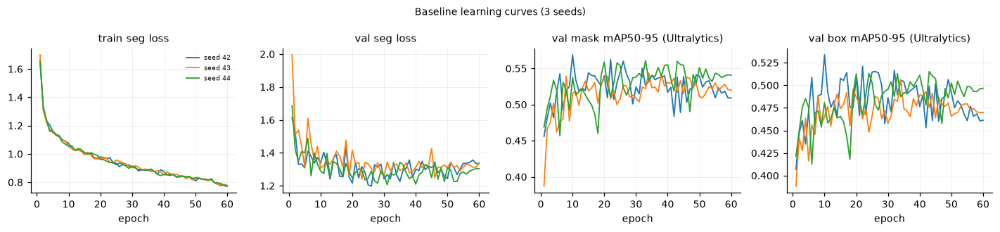

In [7]:
assert SEL is not None, "ต้องรัน Notebook 02 หัวข้อ 8 ให้ครบก่อน"
BASELINE_RUNS = {int(k): ROOT / v for k, v in SEL["run_dirs"].items()}
BASE_DATA = ROOT / SEL["offline_dataset"]
BASE_RECIPE = SEL["recipe"]
PP_NAME = SEL.get("preprocessing")
for s, rd in BASELINE_RUNS.items():
    done = json.loads((rd / "DONE.json").read_text())
    assert done["best_sha256"] == sha256_file(rd / "weights" / "best.pt"), f"checkpoint changed: {rd}"
rec = dict(baseline_arm=SEL["arm"], data=str(BASE_DATA.relative_to(ROOT)), recipe=BASE_RECIPE, preprocessing=PP_NAME,
           runs={s: str(rd.relative_to(ROOT)) for s, rd in BASELINE_RUNS.items()}, base_weights_sha256=BASE_WEIGHTS_SHA,
           model_yaml=str(YAML_PATH), ultralytics=ultralytics.__version__, env={k: ENV.get(k) for k in ("gpu", "torch_cuda", "cudnn", "packages")})
(SUB["baseline"] / "baseline_record.json").write_text(json.dumps(rec, indent=2, default=str))
print(json.dumps(rec, indent=2, default=str)[:2000])
plot_curves(list(BASELINE_RUNS.values()), [f"seed {s}" for s in BASELINE_RUNS], SUB["baseline"] / "learning_curves", "Baseline learning curves (3 seeds)")

In [8]:
# การทดสอบการทำซ้ำได้: ฝึก 3 epoch สองครั้งด้วย seed 42  [EXPENSIVE ~5 นาที]
if RUN_TRAINING:
    rep = []
    for k in (1, 2):
        rd = train_run(SUB["baseline"] / "repro_check", f"repro{k}", SEED, BASE_DATA, {**BASE_RECIPE, "epochs": 3, "patience": 3,
                       "warmup_epochs": 0.1, "close_mosaic": 1})
        rep.append(read_results_csv(rd).assign(run=k))
    R = pd.concat(rep)
    cols = [c for c in R.columns if c.startswith("train/") or c.startswith("metrics/")]
    diff = (R[R.run == 1][cols].reset_index(drop=True) - R[R.run == 2][cols].reset_index(drop=True)).abs()
    save_table(diff.assign(epoch=range(1, len(diff) + 1)), SUB["baseline"] / "reproducibility_abs_diff.csv")
    print("max |difference| between two identical-seed runs per column:"); print(diff.max().round(6))

New https://pypi.org/project/ultralytics/8.4.182 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.180 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3080 Ti, 11902MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=1, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/supawich/Desktop/Aggregate_Project/implement/research/data/preproc_P5_unsharp_A9_1450497fd9/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/supawich/Desktop/Aggregate_Project/implement/research/weights/yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, 

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 6.2it/s 0.8s

                   all        131        429      0.706      0.665      0.707      0.491      0.747      0.656      0.709      0.531


Speed: 0.5ms preprocess, 0.5ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to /home/supawich/Desktop/Aggregate_Project/implement/research/outputs/03_yolo_experiments/baseline/repro_check/repro2_s42_c93afe05


saved table: outputs/03_yolo_experiments/baseline/reproducibility_abs_diff.csv (3 rows)
max |difference| between two identical-seed runs per column:
train/box_loss          0.0
train/seg_loss          0.0
train/cls_loss          0.0
train/l1_loss           0.0
train/sem_loss          0.0
metrics/precision(B)    0.0
metrics/recall(B)       0.0
metrics/mAP50(B)        0.0
metrics/mAP50-95(B)     0.0
metrics/precision(M)    0.0
metrics/recall(M)       0.0
metrics/mAP50(M)        0.0
metrics/mAP50-95(M)     0.0
dtype: float64


In [9]:
GT_VAL = DEV_DIR / "annotations" / "val_coco.json"
PREPROC_FN = {"P1_grayworld": None, "P2_clahe": None, "P3_gamma_auto": None, "P4_nlmeans": None, "P5_unsharp": None}

def _clahe(img, clip=2.0, grid=8):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB); l, a, b = cv2.split(lab)
    return cv2.cvtColor(cv2.merge([cv2.createCLAHE(clipLimit=clip, tileGridSize=(grid, grid)).apply(l), a, b]), cv2.COLOR_LAB2BGR)
def _grayworld(img):
    f = img.astype(np.float32); m = f.reshape(-1, 3).mean(0)
    return np.clip(f * (m.mean() / np.maximum(m, 1e-6)), 0, 255).astype(np.uint8)
def _denoise(img, h=3):
    return cv2.fastNlMeansDenoisingColored(img, None, h, h, 7, 21)
def _unsharp(img, sigma=1.0, amount=0.5):
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    return cv2.addWeighted(img, 1 + amount, blur, -amount, 0)
# P3 ต้องใช้ค่า TARGET_L จาก Notebook 02 (median ของ L* บน train) ซึ่งบันทึกไว้ใน aug_recipe_selected.json
TARGET_L = (SEL.get("preprocessing_params") or {}).get("TARGET_L")
def _gamma_auto(img, target=TARGET_L):
    L = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[..., 0].mean() / 255
    g = np.log(target / 100) / np.log(max(min(L, 0.99), 0.01))
    return cv2.LUT(img, ((np.arange(256) / 255.0) ** g * 255).clip(0, 255).astype(np.uint8))
PREPROC_FN.update(P1_grayworld=_grayworld, P2_clahe=_clahe, P4_nlmeans=_denoise, P5_unsharp=_unsharp)
if TARGET_L is not None:
    PREPROC_FN["P3_gamma_auto"] = _gamma_auto
TF = PREPROC_FN.get(PP_NAME) if PP_NAME else None
assert PP_NAME is None or TF is not None, f"preprocessing {PP_NAME} must be re-implemented here identically to Notebook 02"

def run_imgsz(rd):
    # ใช้ความละเอียดเดียวกับตอนฝึกของ run นั้น (เช่น 960 สำหรับ arm R1)
    a = Path(rd) / "args.yaml"
    return int(_yaml.safe_load(a.read_text()).get("imgsz", 640)) if a.exists() else 640

def eval_val(rd, label="val", records=None, gt=GT_VAL, transform=TF, half=False, weights=None):
    rd = Path(rd); w = Path(weights) if weights else rd / "weights" / "best.pt"
    records = VAL if records is None else records
    f = rd / "eval" / f"summary_{label}.json"
    if f.exists():
        return json.loads(f.read_text())
    dets = cached_dets(rd / "eval" / f"dets_{label}.json.gz", lambda: predict_dets(w, records, imgsz=run_imgsz(rd), transform=transform, half=half, desc=label))
    res = l1_evaluate(gt, dets, records); res_s = l1_evaluate(gt, dets, records, strict=True)
    sc = state_scores(dets, records); th = fit_state_thresholds(sc, records); l2, _ = l2_evaluate(sc, records, th)
    out = dict(**summarize_l1(res), **summarize_l1(res_s, "strict_"), l2_macro_f1=l2["macro_f1"], l2_bal_acc=l2["balanced_accuracy"])
    f.parent.mkdir(parents=True, exist_ok=True); f.write_text(json.dumps(out, indent=2))
    return out

BASE_VAL = pd.DataFrame([dict(seed=s, **eval_val(rd)) for s, rd in BASELINE_RUNS.items()])
save_table(BASE_VAL, SUB["baseline"] / "baseline_val_metrics.csv")
BASE_VAL[["seed", "mask_AP", "mask_AP50", "mask_AP_gravel", "mask_AP_sand", "box_AP", "strict_mask_AP", "l2_macro_f1"]].round(4)

predicted 131 images -> 6728 detections in 3.0s val


predicted 131 images -> 4305 detections in 2.1s val


predicted 131 images -> 3614 detections in 1.9s val


saved table: outputs/03_yolo_experiments/baseline/baseline_val_metrics.csv (3 rows)


,seed,mask_AP,mask_AP50,mask_AP_gravel,mask_AP_sand,box_AP,strict_mask_AP,l2_macro_f1
0,42,0.5823,0.7934,0.7111,0.4536,0.5550,0.5692,0.9538
1,43,0.5443,0.7369,0.6686,0.4200,0.5164,0.5321,0.6518
2,44,0.5647,0.7348,0.7112,0.4181,0.5231,0.5523,0.6919


## 3. Feature map จาก activation จริงของทุกชั้น

**Method** ลงทะเบียน forward hook กับทุก module ระดับบนสุดของ `model.model` (ชั้น 0–23) และ module ย่อยของ C3k2 (`cv1`, `cv2`, bottleneck ภายใน `m`) ของ SPPF, C2PSA และ head (`Segment26`: proto และ branch ของแต่ละ scale) แล้วรันภาพตัวอย่างหนึ่งภาพ (ภาพแรกของชุดตัวอย่างใน Notebook 02) ผ่าน checkpoint baseline seed 42 ในโหมด eval

สำหรับแต่ละชั้นบันทึก index, ชนิดของ module, shape ของ input และ output, stride เทียบกับ input (640 / ความกว้างของ feature map) และสถิติของ activation จากนั้นแสดง grid ของ 16 channel ที่มีค่าเฉลี่ยของ |activation| สูงสุด และภาพค่าเฉลี่ยของทุก channel

**Rationale** การดู activation ของแต่ละชั้นแสดงว่าข้อมูลเชิงพื้นที่ถูกลดความละเอียดและรวมกันอย่างไรตั้งแต่ stem จนถึง head ซึ่งใช้อธิบายผลเรื่องวัตถุเล็กและเนื้อผิว

**Reference** Zeiler & Fergus (2014), *ECCV* — การแสดง activation ของชั้นกลางเพื่อทำความเข้าใจ CNN [รอตรวจ]

**สิ่งที่สรุปไม่ได้จากภาพเหล่านี้** activation สูงไม่ได้แปลว่าเป็นเหตุผลของการตัดสินใจของแบบจำลอง; channel ที่แสดงเลือกตามขนาดของค่า ไม่ได้เลือกตามความหมาย; ภาพเดียวไม่ได้แทนพฤติกรรมของทั้งชุดข้อมูล; และการ normalize ทีละ channel ทำให้เปรียบเทียบขนาดของ activation ระหว่าง channel ในภาพเดียวกันไม่ได้

In [10]:
from ultralytics.data.augment import LetterBox

def letterbox_tensor(img_bgr, size=640):
    lb = LetterBox(new_shape=(size, size), auto=False)(image=img_bgr)
    x = torch.from_numpy(lb[..., ::-1].copy()).permute(2, 0, 1).float().div(255).unsqueeze(0)
    return x, lb

def first_tensor(o):
    if torch.is_tensor(o):
        return o
    if isinstance(o, (list, tuple)):
        for v in o:
            t = first_tensor(v)
            if t is not None:
                return t
    if isinstance(o, dict):
        for v in o.values():
            t = first_tensor(v)
            if t is not None:
                return t
    return None

def shape_of(o):
    if torch.is_tensor(o):
        return list(o.shape)
    if isinstance(o, (list, tuple)):
        return [shape_of(v) for v in o]
    if isinstance(o, dict):
        return {k: shape_of(v) for k, v in o.items()}
    return str(type(o).__name__)

def capture_activations(seg_model, x, include_children=True):
    acts, hooks = {}, []
    def reg(name, mod):
        def hook(m, inp, out):
            acts[name] = dict(module=type(m).__name__, in_shape=shape_of(inp), out_shape=shape_of(out), out=first_tensor(out))
        hooks.append(mod.register_forward_hook(hook))
    for m in seg_model.model:
        reg(f"{m.i:02d}_{type(m).__name__}", m)
        if include_children:
            for cname, child in m.named_children():
                if cname in ("cv1", "cv2", "m", "proto", "cv4", "cv3", "att", "attn", "ffn", "one2one_cv3", "one2one_cv4"):
                    if isinstance(child, nn.ModuleList):
                        for j, cc in enumerate(child):
                            reg(f"{m.i:02d}_{type(m).__name__}.{cname}[{j}]", cc)
                    else:
                        reg(f"{m.i:02d}_{type(m).__name__}.{cname}", child)
    seg_model.eval()
    with torch.no_grad():
        y = seg_model(x)
    for h in hooks:
        h.remove()
    return acts, y

FM_RUN = BASELINE_RUNS[min(BASELINE_RUNS)]
fm_model = YOLO(str(FM_RUN / "weights" / "best.pt")).model.float().to("cuda" if torch.cuda.is_available() else "cpu")
FM_IMG = pd.read_csv(ROOT / "outputs" / "02_preprocessing_augmentation" / "tables" / "sample_set.csv").iloc[0]
FM_PATH = str(DEV_DIR / "train" / "images" / FM_IMG.silver_name)
img = cv2.imread(FM_PATH); img = TF(img) if TF else img
x, lb_img = letterbox_tensor(img)
ACTS, _ = capture_activations(fm_model, x.to(next(fm_model.parameters()).device))
print(f"captured {len(ACTS)} activations from {FM_RUN.relative_to(ROOT)} on {FM_IMG.silver_name}")

captured 70 activations from outputs/02_preprocessing_augmentation/runs/A9_selected_s42_225a7ce9 on 0968__f9b12ec3-0036-45f7-8cc3-4d2e6f481cdc_mp4-0055_jpg.rf.4596d0f3b0d88ac8d38bf7b6ba00d1b0.jpg


In [11]:
FM_DIR = SUB["feature_maps"] / f"baseline_s{min(BASELINE_RUNS)}"
FM_DIR.mkdir(parents=True, exist_ok=True)
meta = []
for name, a in ACTS.items():
    t = a["out"]
    if t is None or t.dim() != 4:
        meta.append(dict(layer=name, module=a["module"], in_shape=str(a["in_shape"]), out_shape=str(a["out_shape"]), stride=None, visualized=False))
        continue
    f = t[0].float().cpu().numpy()                       # (C, H, W)
    C, H, W = f.shape; stride = 640 / W
    absmean = np.abs(f).mean(axis=(1, 2)); top = np.argsort(-absmean)[:16]
    d = FM_DIR / name.replace("/", "_"); d.mkdir(exist_ok=True)
    fig, axes = plt.subplots(4, 5, figsize=(10, 8.2))
    axes[0, 0].imshow(cv2.cvtColor(lb_img, cv2.COLOR_BGR2RGB)); axes[0, 0].set_title("input (letterbox)", fontsize=7)
    axes[0, 1].imshow(f.mean(0), cmap="viridis"); axes[0, 1].set_title(f"mean over {C} ch", fontsize=7)
    axes[0, 2].imshow(np.abs(f).max(0), cmap="viridis"); axes[0, 2].set_title("max |act| over ch", fontsize=7)
    axes[0, 3].bar(range(C), np.sort(absmean)[::-1], color="#0072B2", width=1.0); axes[0, 3].set_title("channel mean |act| (sorted)", fontsize=7)
    axes[0, 4].hist(f.ravel(), bins=60, color="#555555"); axes[0, 4].set_title("activation histogram", fontsize=7)
    for ax, ch in zip(axes[1:].ravel(), top):
        ax.imshow(f[ch], cmap="viridis"); ax.set_title(f"ch {ch} (|μ|={absmean[ch]:.2f})", fontsize=6)
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for ax in axes[1:].ravel()[len(top):]:
        ax.axis("off")
    fig.suptitle(f"{name} | in {a['in_shape']} -> out {list(t.shape)} | stride {stride:.0f}", fontsize=8)
    fig.tight_layout(); fig.savefig(d / "activation_grid.png", dpi=150); plt.close(fig)
    m = dict(layer=name, module=a["module"], in_shape=str(a["in_shape"]), out_shape=str(a["out_shape"]), channels=C, H=H, W=W,
             stride=stride, act_mean=float(f.mean()), act_std=float(f.std()), act_abs_max=float(np.abs(f).max()),
             frac_zero=float((f <= 0).mean()), top16_channels=top.tolist(), visualized=True)
    (d / "metadata.json").write_text(json.dumps(m, indent=2)); meta.append(m)
FM_META = pd.DataFrame(meta)
save_table(FM_META, FM_DIR / "layers_metadata.csv")
print(f"saved {int(FM_META.visualized.sum())} layer visualizations to {FM_DIR.relative_to(ROOT)}")
FM_META[["layer", "module", "in_shape", "out_shape", "stride", "act_std", "frac_zero"]].head(40)

saved table: outputs/03_yolo_experiments/feature_maps/baseline_s42/layers_metadata.csv (70 rows)
saved 69 layer visualizations to outputs/03_yolo_experiments/feature_maps/baseline_s42


,layer,module,in_shape,out_shape,stride,act_std,frac_zero
0,00_Conv,Conv,"[[1, 3, 640, 640]]","[1, 16, 320, 320]",2.0,4.177315,0.409312
1,01_Conv,Conv,"[[1, 16, 320, 320]]","[1, 32, 160, 160]",4.0,3.047270,0.359250
2,02_C3k2.cv1,Conv,"[[1, 32, 160, 160]]","[1, 32, 160, 160]",4.0,1.612427,0.203562
3,02_C3k2.m[0],Bottleneck,"[[1, 16, 160, 160]]","[1, 16, 160, 160]",4.0,2.619110,0.041199
4,02_C3k2.cv2,Conv,"[[1, 48, 160, 160]]","[1, 64, 160, 160]",4.0,1.296096,0.332985
5,02_C3k2,C3k2,"[[1, 32, 160, 160]]","[1, 64, 160, 160]",4.0,1.296096,0.332985
6,03_Conv,Conv,"[[1, 64, 160, 160]]","[1, 64, 80, 80]",8.0,1.079387,0.358350
7,04_C3k2.cv1,Conv,"[[1, 64, 80, 80]]","[1, 64, 80, 80]",8.0,0.814947,0.202615
8,04_C3k2.m[0],Bottleneck,"[[1, 32, 80, 80]]","[1, 32, 80, 80]",8.0,0.939294,0.068770
9,04_C3k2.cv2,Conv,"[[1, 96, 80, 80]]","[1, 128, 80, 80]",8.0,0.390735,0.703560


saved figure: outputs/03_yolo_experiments/feature_maps/baseline_s42/overview_all_layers.png|pdf


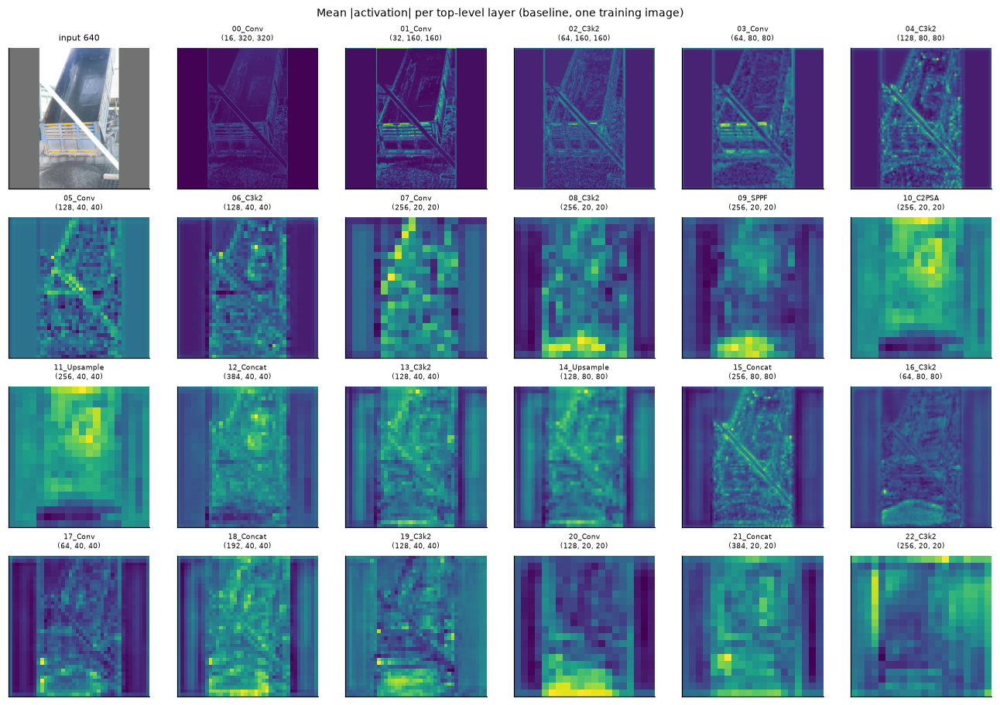

In [12]:
# ภาพรวม: ค่าเฉลี่ยของ |activation| ของทุกชั้นระดับบนสุดในรูปเดียว
top_layers = [n for n in ACTS if "." not in n and ACTS[n]["out"] is not None and ACTS[n]["out"].dim() == 4]
nc = 6; nr = int(np.ceil((len(top_layers) + 1) / nc))
fig, axes = plt.subplots(nr, nc, figsize=(nc * 2.0, nr * 2.1))
axes = axes.ravel()
axes[0].imshow(cv2.cvtColor(lb_img, cv2.COLOR_BGR2RGB)); axes[0].set_title("input 640", fontsize=7)
for ax, n in zip(axes[1:], top_layers):
    t = ACTS[n]["out"][0].float().abs().mean(0).cpu().numpy()
    ax.imshow(t, cmap="viridis"); ax.set_title(f"{n}\n{tuple(ACTS[n]['out'].shape[1:])}", fontsize=6)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for ax in axes[len(top_layers) + 1:]:
    ax.axis("off")
fig.suptitle("Mean |activation| per top-level layer (baseline, one training image)", fontsize=9)
fig.tight_layout(); savefig(fig, FM_DIR / "overview_all_layers"); plt.show()

## 4. ต้นทุนการคำนวณรายชั้นและทั้งแบบจำลอง

**Method**

- **รายชั้น:** สำหรับทุก module ระดับบนสุด ใช้ input ที่ capture ได้จริงจากหัวข้อ 3 แล้ววัด (1) จำนวนพารามิเตอร์ (2) FLOPs ด้วย thop (`ultralytics-thop`, นับ MAC แล้วคูณ 2 = FLOPs) (3) shape ของ input/output (4) หน่วยความจำของ activation = จำนวนสมาชิกของ output × 4 ไบต์ (FP32) และ (5) latency ของ module เดี่ยวด้วย CUDA event: warm-up 50 รอบ วัด 200 รอบ รายงาน median ทั้ง FP32 และ FP16
- **ทั้งแบบจำลอง:** latency ของ forward pass (ไม่รวม pre/post-processing) ที่ batch 1, 8 และ 16, FP32 และ FP16, warm-up 50 รอบ วัด 300 รอบด้วย `torch.cuda.synchronize()` รายงาน p50, p95, throughput (ภาพ/วินาที) และหน่วยความจำ GPU สูงสุด (`torch.cuda.max_memory_allocated`) และแยกเวลาของ preprocess / inference / postprocess จาก `Results.speed` ของ Ultralytics

**Rationale** FLOPs เป็นต้นทุนเชิงทฤษฎีที่ไม่สะท้อนเวลาจริงโดยตรง เพราะเวลาจริงขึ้นกับการเคลื่อนย้ายข้อมูลในหน่วยความจำ จำนวน kernel launch และความเหมาะสมของ kernel กับ shape ของ tensor

**Reference** Ma et al. (2018), "ShuffleNet V2", *ECCV* — FLOPs เป็นตัวชี้วัดทางอ้อมของความเร็ว และ memory access cost มีผลมาก [รอตรวจ]; Dehghani et al. (2022), "The Efficiency Misnomer", *ICLR* [รอตรวจ]; CUDA asynchronous execution ต้อง synchronize ก่อนอ่านเวลา (PyTorch CUDA semantics)

**Limitation** latency ของ module เดี่ยวรวม overhead ของการเรียกจาก Python และไม่รวมผลของการรวม kernel ในการรันทั้งแบบจำลอง ผลรวมของ latency รายชั้นจึงไม่เท่ากับ latency ของทั้งแบบจำลอง; ค่าที่วัดเป็นของ RTX 3080 Ti ในเครื่องนี้เท่านั้น

In [13]:
from ultralytics.utils.torch_utils import get_flops
import copy

def layer_inputs(seg_model, x):
    # รัน forward ทีละชั้นตามกราฟ (เหมือน BaseModel._predict_once) เพื่อเก็บ input จริงของแต่ละชั้น
    y, inputs = [], {}
    for m in seg_model.model:
        if m.f != -1:
            xin = y[m.f] if isinstance(m.f, int) else [x if j == -1 else y[j] for j in m.f]
        else:
            xin = x
        inputs[m.i] = xin
        x = m(xin)
        y.append(x if m.i in seg_model.save else None)
    return inputs

def thop_flops(m, xin):
    from thop import profile
    with contextlib.redirect_stdout(io.StringIO()):
        macs, _ = profile(copy.deepcopy(m), inputs=(xin,), verbose=False)
    return 2 * macs

def cuda_time(fn, warmup=50, iters=200):
    st, en = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
    for _ in range(warmup):
        fn()
    torch.cuda.synchronize(); ts = []
    for _ in range(iters):
        st.record(); fn(); en.record(); torch.cuda.synchronize(); ts.append(st.elapsed_time(en))
    return np.asarray(ts)

def to_half(o):
    if torch.is_tensor(o):
        return o.half()
    return [to_half(v) for v in o]

def numel_bytes(o, b=4):
    if torch.is_tensor(o):
        return o.numel() * b
    if isinstance(o, (list, tuple)):
        return sum(numel_bytes(v, b) for v in o)
    if isinstance(o, dict):
        return sum(numel_bytes(v, b) for v in o.values())
    return 0

dev = torch.device("cuda")
bm = YOLO(str(FM_RUN / "weights" / "best.pt")).model.float().to(dev).eval()
x640 = torch.rand(1, 3, 640, 640, device=dev)
with torch.no_grad():
    INP = layer_inputs(bm, x640)
    rows = []
    for m in bm.model:
        xin = INP[m.i]
        out = m(xin)
        fl = thop_flops(m, xin)
        t32 = cuda_time(lambda: m(xin))
        mh = copy.deepcopy(m).half(); xh = to_half(xin)
        t16 = cuda_time(lambda: mh(xh))
        rows.append(dict(idx=m.i, module=type(m).__name__, params=sum(p.numel() for p in m.parameters()), GFLOPs=fl / 1e9,
                         in_shape=str(shape_of(xin)), out_shape=str(shape_of(out)), act_MB_fp32=numel_bytes(out) / 2**20,
                         lat_ms_fp32_median=float(np.median(t32)), lat_ms_fp16_median=float(np.median(t16))))
LAYER = pd.DataFrame(rows)
LAYER["GFLOPs_share"] = LAYER.GFLOPs / LAYER.GFLOPs.sum(); LAYER["lat_share_fp32"] = LAYER.lat_ms_fp32_median / LAYER.lat_ms_fp32_median.sum()
save_table(LAYER, SUB["layer_benchmarks"] / "per_layer_cost.csv")
print(f"sum of per-layer GFLOPs @640: {LAYER.GFLOPs.sum():.2f} | Ultralytics get_flops: {get_flops(bm, 640):.2f}")
LAYER.round(4)

saved table: outputs/03_yolo_experiments/layer_benchmarks/per_layer_cost.csv (24 rows)
sum of per-layer GFLOPs @640: 10.42 | Ultralytics get_flops: 10.42


,idx,module,params,GFLOPs,in_shape,out_shape,act_MB_fp32,lat_ms_fp32_median,lat_ms_fp16_median,GFLOPs_share,lat_share_fp32
0,0,Conv,464,0.1016,"[1, 3, 640, 640]","[1, 16, 320, 320]",6.2500,0.1290,0.1024,0.0097,0.0217
1,1,Conv,4672,0.2425,"[1, 16, 320, 320]","[1, 32, 160, 160]",3.1250,0.0707,0.0645,0.0233,0.0119
2,2,C3k2,6640,0.3523,"[1, 32, 160, 160]","[1, 64, 160, 160]",6.2500,0.2035,0.2021,0.0338,0.0343
3,3,Conv,36992,0.4751,"[1, 64, 160, 160]","[1, 64, 80, 80]",1.5625,0.0704,0.0543,0.0456,0.0119
4,4,C3k2,26080,0.3400,"[1, 64, 80, 80]","[1, 128, 80, 80]",3.1250,0.1646,0.2144,0.0326,0.0277
5,5,Conv,147712,0.4735,"[1, 128, 80, 80]","[1, 128, 40, 40]",0.7812,0.0566,0.0533,0.0454,0.0095
6,6,C3k2,87040,0.2818,"[1, 128, 40, 40]","[1, 128, 40, 40]",0.7812,0.3205,0.4065,0.0270,0.0540
7,7,Conv,295424,0.2367,"[1, 128, 40, 40]","[1, 256, 20, 20]",0.3906,0.0489,0.0502,0.0227,0.0082
8,8,C3k2,346112,0.2785,"[1, 256, 20, 20]","[1, 256, 20, 20]",0.3906,0.3420,0.4174,0.0267,0.0576
9,9,SPPF,164608,0.1323,"[1, 256, 20, 20]","[1, 256, 20, 20]",0.3906,0.1148,0.1412,0.0127,0.0193


saved figure: outputs/03_yolo_experiments/layer_benchmarks/per_layer_cost.png|pdf


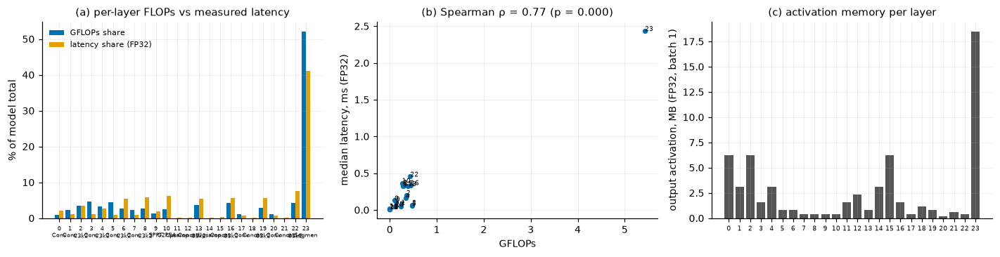

In [14]:
from scipy.stats import spearmanr
rho, pval = spearmanr(LAYER.GFLOPs, LAYER.lat_ms_fp32_median)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
x_ = np.arange(len(LAYER))
axes[0].bar(x_ - 0.2, LAYER.GFLOPs_share * 100, 0.4, color="#0072B2", label="GFLOPs share")
axes[0].bar(x_ + 0.2, LAYER.lat_share_fp32 * 100, 0.4, color="#E69F00", label="latency share (FP32)")
axes[0].set_xticks(x_, [f"{i}\n{m[:6]}" for i, m in zip(LAYER.idx, LAYER.module)], fontsize=5); axes[0].legend(frameon=False, fontsize=7)
axes[0].set_ylabel("% of model total"); axes[0].set_title("(a) per-layer FLOPs vs measured latency")
axes[1].scatter(LAYER.GFLOPs, LAYER.lat_ms_fp32_median, s=14, color="#0072B2")
for r in LAYER.itertuples():
    axes[1].annotate(str(r.idx), (r.GFLOPs, r.lat_ms_fp32_median), fontsize=6)
axes[1].set_xlabel("GFLOPs"); axes[1].set_ylabel("median latency, ms (FP32)"); axes[1].set_title(f"(b) Spearman ρ = {rho:.2f} (p = {pval:.3f})")
axes[2].bar(x_, LAYER.act_MB_fp32, color="#555555"); axes[2].set_xticks(x_, LAYER.idx, fontsize=6)
axes[2].set_ylabel("output activation, MB (FP32, batch 1)"); axes[2].set_title("(c) activation memory per layer")
fig.tight_layout(); savefig(fig, SUB["layer_benchmarks"] / "per_layer_cost"); plt.show()

In [15]:
def model_latency(model, bs, half, warmup=50, iters=300, imgsz=640):
    m = copy.deepcopy(model).to(dev).eval(); m = m.half() if half else m.float()
    xb = torch.rand(bs, 3, imgsz, imgsz, device=dev, dtype=torch.float16 if half else torch.float32)
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    with torch.no_grad():
        t = cuda_time(lambda: m(xb), warmup, iters)
    return dict(batch=bs, precision="fp16" if half else "fp32", p50_ms=float(np.percentile(t, 50)), p95_ms=float(np.percentile(t, 95)),
                mean_ms=float(t.mean()), throughput_img_s=float(bs * 1000 / np.median(t)), peak_mem_MB=torch.cuda.max_memory_allocated() / 2**20)

WHOLE = pd.DataFrame([model_latency(bm, bs, h) for bs in (1, 8, 16) for h in (False, True)])
# เวลาแยก preprocess / inference / postprocess ของ pipeline ของ Ultralytics (batch 1, ภาพจริง 50 ภาพจาก val)
pm = YOLO(str(FM_RUN / "weights" / "best.pt"))
for p in VAL.path.head(10):
    pm.predict(p, imgsz=640, verbose=False)
sp = pd.DataFrame([pm.predict(p, imgsz=640, verbose=False)[0].speed for p in VAL.path.head(50)])
PIPE = sp.describe(percentiles=[0.5, 0.95]).T[["50%", "95%", "mean"]].rename(columns={"50%": "p50_ms", "95%": "p95_ms"})
save_table(WHOLE, SUB["layer_benchmarks"] / "whole_model_latency.csv"); save_table(PIPE.reset_index(), SUB["layer_benchmarks"] / "pipeline_speed_breakdown.csv")
display(WHOLE.round(3)); display(PIPE.round(3))
w1 = WHOLE[(WHOLE.batch == 1) & (WHOLE.precision == "fp32")].p50_ms.iloc[0]
print(f"sum of per-layer median latency (FP32, bs1): {LAYER.lat_ms_fp32_median.sum():.2f} ms vs whole-model p50 {w1:.2f} ms")

saved table: outputs/03_yolo_experiments/layer_benchmarks/whole_model_latency.csv (6 rows)
saved table: outputs/03_yolo_experiments/layer_benchmarks/pipeline_speed_breakdown.csv (3 rows)


,batch,precision,p50_ms,p95_ms,mean_ms,throughput_img_s,peak_mem_MB
0,1,fp32,5.741,6.377,5.876,174.200,269.000
1,1,fp16,6.790,7.320,6.866,147.265,246.271
2,8,fp32,12.459,13.472,12.697,642.083,547.007
3,8,fp16,8.379,9.154,8.525,954.723,410.267
4,16,fp32,23.685,25.567,23.934,675.530,864.534
5,16,fp16,14.454,14.559,14.484,1106.939,589.976


,p50_ms,p95_ms,mean
preprocess,0.522,0.560,0.392
inference,3.293,3.431,3.310
postprocess,0.638,0.692,0.643


sum of per-layer median latency (FP32, bs1): 5.94 ms vs whole-model p50 5.74 ms


## 5. AdamW เทียบกับ MuSGD  [EXPENSIVE]

**Method** ใช้สถาปัตยกรรม ชุดข้อมูล augmentation imgsz จำนวน epoch และการประเมินเดียวกับ baseline ต่างกันเฉพาะ optimizer และ hyperparameter ที่ผูกกับ optimizer

| | AdamW (baseline) | MuSGD |
|---|---|---|
| lr0 / lrf | 0.001 / 0.01 | 0.0054 / 0.05 |
| momentum | β1 = 0.937 | 0.937 (Nesterov) |
| weight decay | 0.0005 | 0.00064 |
| warmup | 3% ของ epochs | 1% ของ epochs |
| ที่มาของค่า | ค่าแนะนำของ Ultralytics สำหรับ AdamW | `train_args` ของ checkpoint ทางการ `yolo26n-seg.pt` (ฝึกบน COCO ด้วย MuSGD, batch 128) |

MuSGD ของ Ultralytics (`ultralytics/optim/muon.py`) ใช้ Muon (orthogonalize update ของพารามิเตอร์ที่เป็น matrix/conv ด้วย Newton–Schulz) ผสมกับ SGD และเพิ่ม lr 3 เท่าให้ head บางส่วนเมื่อ fine-tune (ตาม `build_optimizer` ในเวอร์ชันที่ติดตั้ง)

**Rationale** งานเดิมเปรียบเทียบด้วย seed เดียว 30 epoch และ MuSGD ยังไม่ลู่เข้า การเปรียบเทียบนี้ใช้งบเท่ากับ baseline และ 3 seed

**Reference** Loshchilov & Hutter (2019), "Decoupled Weight Decay Regularization", *ICLR* (AdamW) [รอตรวจ]; Jordan et al. (2024) Muon และ Liu et al. (2025), arXiv:2502.16982 [รอตรวจ]; Ultralytics YOLO26 documentation (MuSGD) [รอตรวจ]

**Limitation** ค่า MuSGD มาจากการฝึกบน COCO ที่ batch 128 ซึ่งอาจไม่เหมาะกับ batch 16 และข้อมูลขนาดเล็ก ผลจึงเปรียบเทียบ optimizer ภายใต้ค่าที่ผู้พัฒนาแนะนำ ไม่ใช่ภายใต้ค่าที่ปรับดีที่สุดของแต่ละตัว และ 3 seed ไม่พอสำหรับการทดสอบทางสถิติที่มีอำนาจสูง

**รอบที่สอง:** ไม่ฝึก MuSGD ใหม่ (`RUN_MUSGD = False`) เพราะผู้วิจัยกำหนดให้ใช้ AdamW รอบแรก MuSGD ได้ mask AP ต่ำกว่า AdamW ทุก seed (ผลต่างแบบคู่ −0.016 ± 0.008) ผลอยู่ใน `outputs/_archive_round1/03_evaluation/optimizer_summary.csv`

In [16]:
MUSGD_RECIPE = {**BASE_RECIPE, "optimizer": "MuSGD", "lr0": 0.0054, "lrf": 0.05, "momentum": 0.937, "weight_decay": 0.00064,
                "warmup_epochs": round(1 * BASE_RECIPE["epochs"] / 100, 2)}
OPT_RUNS = {"AdamW": dict(BASELINE_RUNS), "MuSGD": {}}
RUN_MUSGD = False   # รอบที่สองใช้ AdamW ตามที่ผู้วิจัยกำหนด ผล MuSGD ของรอบแรกอยู่ใน outputs/_archive_round1/
if RUN_TRAINING and RUN_MUSGD:
    for s in sorted(BASELINE_RUNS):
        OPT_RUNS["MuSGD"][s] = train_run(SUB["optimizer_comparison"], "MuSGD", s, BASE_DATA, MUSGD_RECIPE)

In [17]:
if OPT_RUNS["MuSGD"]:
    rows = []
    for opt, runs in OPT_RUNS.items():
        for s, rd in runs.items():
            ev = eval_val(rd)
            ep = pd.read_csv(Path(rd) / "epoch_log.csv")
            res = read_results_csv(rd)
            loss_cols = [c for c in res.columns if c.startswith("train/") and c.endswith("loss")]
            tot = res[loss_cols].sum(axis=1)
            rows.append(dict(optimizer=opt, seed=s, **{k: ev[k] for k in ("mask_AP", "mask_AP_gravel", "mask_AP_sand", "box_AP", "l2_macro_f1")},
                             best_epoch=int(res["metrics/mAP50-95(M)"].idxmax()) + 1, final_train_loss=float(tot.iloc[-1]),
                             loss_volatility_last20pct=float(tot.diff().iloc[-max(2, len(tot) // 5):].std()),
                             wall_min=float((Path(rd) / "wall_time_s.txt").read_text()) / 60 if (Path(rd) / "wall_time_s.txt").exists() else np.nan,
                             gpu_peak_reserved_gb=float(ep.gpu_peak_reserved_gb.max())))
    OPT = pd.DataFrame(rows)
    save_table(OPT, SUB["optimizer_comparison"] / "optimizer_runs.csv")
    agg = OPT.groupby("optimizer").agg(["mean", "std"]).drop(columns="seed")
    save_table(agg.reset_index(), SUB["optimizer_comparison"] / "optimizer_summary.csv")
    display(agg.round(4))
    d = OPT.pivot(index="seed", columns="optimizer", values="mask_AP"); diff = (d["MuSGD"] - d["AdamW"])
    print(f"paired difference MuSGD − AdamW (same seed): mean {diff.mean():.4f}, SD {diff.std(ddof=1):.4f}, per seed {diff.round(4).to_dict()}")
    plot_curves([*OPT_RUNS["AdamW"].values(), *OPT_RUNS["MuSGD"].values()],
                [f"AdamW s{s}" for s in OPT_RUNS["AdamW"]] + [f"MuSGD s{s}" for s in OPT_RUNS["MuSGD"]],
                SUB["optimizer_comparison"] / "learning_curves", "AdamW vs MuSGD (same data, recipe and budget)")

## 6. Attention module และ ablation ของสถาปัตยกรรม  [EXPENSIVE]

**Method** แทรก attention ที่ output ของ C3k2 ใน neck ซึ่งเป็น feature ที่ส่งเข้า head โดยตรง: ชั้น 16 (P3/8), 19 (P4/16), 22 (P5/32) และทดลองทีละการแก้ไข

| Arm | การแก้ไข |
|---|---|
| B | baseline |
| C1 | CBAM ที่ P3 (ชั้น 16) |
| C2 | ECA ที่ P3 |
| C3 | CBAM ที่ P3, P4, P5 |
| C4 | ECA ที่ P3, P4, P5 |
| A0–A4 | C3k2 พร้อม attention ของ Ultralytics (`attn=True`) ดูหัวข้อ 6.1 |

**Implementation**

- CBAM ใน Ultralytics (`nn/modules/conv.py`) ใช้ channel attention แบบ RTMDet (avg-pool และ conv 1×1 ชั้นเดียว) ไม่ใช่แบบในบทความต้นฉบับ notebook นี้จึง implement CBAM ตาม Woo et al. (2018): avg-pool และ max-pool ผ่าน MLP ร่วม (reduction 16) ตามด้วย spatial attention 7×7
- ECA ตาม Wang et al. (2020): kernel ของ conv 1D ขนาด k = |log2(C)/γ + b/γ| (ปัดเป็นเลขคี่, γ = 2, b = 1)
- ทั้งสองโมดูลปรับให้เริ่มต้นเป็น identity (น้ำหนัก = 2·sigmoid(z) และชั้นสุดท้ายเริ่มที่ศูนย์) เพื่อไม่ทำลาย feature ของแบบจำลองที่ pretrain แล้วตอนเริ่ม fine-tune นี่เป็นการปรับจากบทความต้นฉบับ (บทความใช้ sigmoid ที่ไม่สเกล) ซึ่งต้องรายงาน
- การแทรกทำด้วยการเปลี่ยน class ของ C3k2 เดิมเป็น `C3k2Att` ซึ่งเพิ่มเพียง submodule `att` ชื่อพารามิเตอร์เดิมไม่เปลี่ยน จึงโอน pretrained weights ได้ครบทุก tensor ของชั้นเดิม (รายงานใน `TRANSFER_LOG`)
- ใช้สูตรและงบการฝึกเดียวกับ baseline, 2 seed (42, 43)

**Reference** Woo et al. (2018), "CBAM", *ECCV* [รอตรวจ]; Wang et al. (2020), "ECA-Net", *CVPR* [รอตรวจ]

**Limitation** การเริ่มต้นแบบ identity อาจเปลี่ยนพลวัตของการเรียนรู้เมื่อเทียบกับบทความ และ 2 seed ไม่พอสำหรับสรุปความต่างขนาดเล็ก การตัดสินใช้เกณฑ์เดียวกับ Notebook 02 (ต้องดีกว่า baseline เกินส่วนเบี่ยงเบนมาตรฐานของ baseline)

**รอบที่สอง:** ฝึกใหม่เฉพาะ C1 (CBAM ที่ P3) และ A0 (ถอด attention ชั้น 22) ซึ่งเป็น arm ที่ดีที่สุดของแต่ละกลุ่มในรอบแรก ส่วน C2–C4 และ A1–A4 แพ้ baseline ชัดเจนในรอบแรก (−0.01 ถึง −0.04) และรายงานจาก `outputs/_archive_round1/03_evaluation/`

In [18]:
ATT_ARMS_ROUND1 = {"C1_cbam_P3": ("cbam", [16]), "C2_eca_P3": ("eca", [16]), "C3_cbam_P345": ("cbam", [16, 19, 22]), "C4_eca_P345": ("eca", [16, 19, 22])}
# รอบที่สองฝึกใหม่เฉพาะ arm ที่ดีที่สุดของรอบแรก (C1) ส่วน arm อื่นรายงานจากรอบแรก (outputs/_archive_round1/)
ATT_ARMS = {"C1_cbam_P3": ATT_ARMS_ROUND1["C1_cbam_P3"]}
ATT_SEEDS = [42, 43]
# ตรวจว่าชั้น 16/19/22 เป็น C3k2 และการแทรกไม่เปลี่ยนจำนวนพารามิเตอร์ของชั้นเดิม
chk = YOLO(str(BASE_WEIGHTS)).model
n0 = sum(p.numel() for p in chk.parameters())
for arm, (kind, layers) in ATT_ARMS.items():
    t = copy.deepcopy(chk); insert_attention(t, kind, layers)
    n1 = sum(p.numel() for p in t.parameters())
    with torch.no_grad():
        y0 = chk.float().eval()(torch.rand(1, 3, 640, 640)); y1 = t.float().eval()(torch.rand(1, 3, 640, 640))
    print(f"{arm}: +{n1 - n0} params ({(n1 / n0 - 1) * 100:.2f}%)")
ATT_RUNS = defaultdict(dict)
if RUN_TRAINING:
    for arm, (kind, layers) in ATT_ARMS.items():
        for s in ATT_SEEDS:
            ATT_SPEC.update(kind=kind, layers=layers)
            ATT_RUNS[arm][s] = train_run(SUB["architecture_ablations"], arm, s, BASE_DATA, {**BASE_RECIPE}, trainer=AttSegTrainer)
    pd.DataFrame(TRANSFER_LOG).to_csv(SUB["architecture_ablations"] / "weight_transfer.csv", index=False)
    display(pd.DataFrame(TRANSFER_LOG))

C1_cbam_P3: +610 params (0.02%)


New https://pypi.org/project/ultralytics/8.4.182 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.180 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3080 Ti, 11902MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=6, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/supawich/Desktop/Aggregate_Project/implement/research/data/preproc_P5_unsharp_A9_1450497fd9/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/supawich/Desktop/Aggregate_Project/implement/research/weights/yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0,

Overriding model.yaml nc=80 with nc=2


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 6.4it/s 0.8s

                   all        131        429      0.752      0.729      0.753      0.536       0.76      0.737      0.763      0.575


Speed: 0.6ms preprocess, 0.5ms inference, 0.0ms loss, 1.1ms postprocess per image


Results saved to /home/supawich/Desktop/Aggregate_Project/implement/research/outputs/03_yolo_experiments/architecture_ablations/C1_cbam_P3_s43_7bd78250


,kind,layers,tensors_matched,tensors_total,params_matched,params_total
0,cbam,[16],740,847,2983470,3074974
1,cbam,[16],740,847,2983470,3074974


In [19]:
if ATT_RUNS:
    rows = [dict(arm="B_baseline", seed=s, **eval_val(rd)) for s, rd in BASELINE_RUNS.items() if s in ATT_SEEDS]
    for arm, runs in ATT_RUNS.items():
        for s, rd in runs.items():
            ATT_SPEC.update(kind=ATT_ARMS[arm][0], layers=ATT_ARMS[arm][1])
            rows.append(dict(arm=arm, seed=s, **eval_val(rd)))
    ABL = pd.DataFrame(rows)
    b_all = BASE_VAL.mask_AP; b_mean, b_sd = b_all.mean(), b_all.std(ddof=1)
    agg = ABL.groupby("arm")[["mask_AP", "mask_AP_gravel", "mask_AP_sand", "mask_APs", "l2_macro_f1"]].agg(["mean", "std"])
    agg[("decision", "beats_baseline")] = (agg[("mask_AP", "mean")] - b_mean) > b_sd
    for arm in ATT_ARMS:
        w = ATT_RUNS[arm][ATT_SEEDS[0]] / "weights" / "best.pt"
        mdl = YOLO(str(w)).model
        agg.loc[arm, ("cost", "params")] = sum(p.numel() for p in mdl.parameters())
        agg.loc[arm, ("cost", "GFLOPs")] = get_flops(mdl, 640)
        agg.loc[arm, ("cost", "lat_p50_ms_fp16_bs1")] = model_latency(mdl, 1, True)["p50_ms"]
    agg.loc["B_baseline", ("cost", "params")] = sum(p.numel() for p in bm.parameters())
    agg.loc["B_baseline", ("cost", "GFLOPs")] = get_flops(bm, 640)
    agg.loc["B_baseline", ("cost", "lat_p50_ms_fp16_bs1")] = model_latency(bm, 1, True)["p50_ms"]
    save_table(ABL, SUB["architecture_ablations"] / "attention_runs.csv"); save_table(agg.reset_index(), SUB["architecture_ablations"] / "attention_summary.csv")
    print(f"baseline (3 seeds): mean {b_mean:.4f}, SD {b_sd:.4f}")
    display(agg.round(4))

predicted 131 images -> 5534 detections in 2.4s val


predicted 131 images -> 4459 detections in 2.0s val


saved table: outputs/03_yolo_experiments/architecture_ablations/attention_runs.csv (4 rows)
saved table: outputs/03_yolo_experiments/architecture_ablations/attention_summary.csv (2 rows)
baseline (3 seeds): mean 0.5638, SD 0.0190


mask_AP         mask_AP_gravel         mask_AP_sand          \
              mean     std           mean     std         mean     std   
arm                                                                      
B_baseline  0.5633  0.0269         0.6898  0.0300       0.4368  0.0237   
C1_cbam_P3  0.5897  0.0075         0.7311  0.0146       0.4483  0.0004   

           mask_APs         l2_macro_f1               decision       cost  \
               mean     std        mean     std beats_baseline     params   
arm                                                                         
B_baseline   0.0950  0.0265      0.8028  0.2136          False  3083302.0   
C1_cbam_P3   0.1115  0.0093      0.7106  0.0930           True  3083912.0   

                                         
             GFLOPs lat_p50_ms_fp16_bs1  
arm                                      
B_baseline  10.4207              6.8190  
C1_cbam_P3  10.4220              7.0682

saved figure: outputs/03_yolo_experiments/feature_maps/C1_cbam_P3_s42/attention_layer16.png|pdf


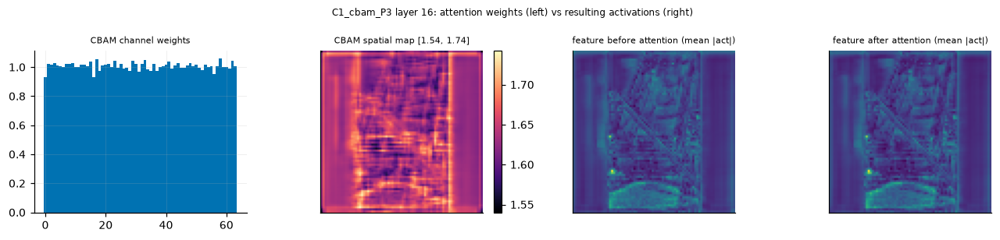

In [20]:
# ค่า attention ที่แบบจำลองคำนวณจริงบนภาพเดียวกับหัวข้อ 3 (แยกน้ำหนัก attention ออกจาก feature ที่ผ่าน attention)
if ATT_RUNS:
    ATT_RECORD["on"] = True
    for arm, (kind, layers) in ATT_ARMS.items():
        mdl = YOLO(str(ATT_RUNS[arm][ATT_SEEDS[0]] / "weights" / "best.pt")).model.float().to(dev).eval()
        acts, _ = capture_activations(mdl, x.to(dev))
        d = SUB["feature_maps"] / f"{arm}_s{ATT_SEEDS[0]}"; d.mkdir(parents=True, exist_ok=True)
        for li in layers:
            att = mdl.model[li].att
            fig, axes = plt.subplots(1, 4, figsize=(12, 2.8))
            pre = acts[f"{li:02d}_C3k2Att.cv2"]["out"][0].float().abs().mean(0).cpu().numpy() if f"{li:02d}_C3k2Att.cv2" in acts else None
            post = acts[f"{li:02d}_C3k2Att"]["out"][0].float().abs().mean(0).cpu().numpy()
            if kind == "eca":
                w = att.last_weights[0, :, 0, 0].numpy()
                axes[0].bar(range(len(w)), w, color="#0072B2", width=1.0); axes[0].set_title(f"ECA channel weights (k={att.k})", fontsize=7)
                axes[1].axis("off")
            else:
                w = att.last_channel[0, :, 0, 0].numpy(); sa = att.last_spatial[0, 0].numpy()
                axes[0].bar(range(len(w)), w, color="#0072B2", width=1.0); axes[0].set_title("CBAM channel weights", fontsize=7)
                im = axes[1].imshow(sa, cmap="magma"); axes[1].set_title(f"CBAM spatial map [{sa.min():.2f}, {sa.max():.2f}]", fontsize=7)
                plt.colorbar(im, ax=axes[1], fraction=0.046)
            if pre is not None:
                axes[2].imshow(pre, cmap="viridis"); axes[2].set_title("feature before attention (mean |act|)", fontsize=7)
            axes[3].imshow(post, cmap="viridis"); axes[3].set_title("feature after attention (mean |act|)", fontsize=7)
            for ax in axes[1:]:
                ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            fig.suptitle(f"{arm} layer {li}: attention weights (left) vs resulting activations (right)", fontsize=8)
            fig.tight_layout(); savefig(fig, d / f"attention_layer{li}"); plt.show()
            np.save(d / f"attention_layer{li}_channel_weights.npy", w)
    ATT_RECORD["on"] = False

### 6.1 C3k2 พร้อม attention ของ Ultralytics (`attn=True`)  [EXPENSIVE]

**Method** โมดูล `C3k2` ของ Ultralytics มีตัวเลือก `attn=True` ซึ่งแทนบล็อกภายใน (Bottleneck หรือ C3k) ด้วย `Bottleneck` ตามด้วย `PSABlock` (multi-head self-attention แบบ position-sensitive พร้อม positional encoding แบบ depthwise conv และ feed-forward ที่มี residual) แบบจำลอง YOLO26n-seg ต้นฉบับใช้ attention ลักษณะนี้อยู่แล้วสองตำแหน่ง คือ `C2PSA` ที่ชั้น 10 (ท้าย backbone) และ `C3k2(attn=True)` ที่ชั้น 22 (P5 ของ neck) ส่วนนี้จึงทดสอบทั้งการเพิ่มและการถอด attention ชนิดเดียวกันนี้ที่ตำแหน่งอื่น โดยแก้ไขเฉพาะอาร์กิวเมนต์ `attn` ใน yaml ของสถาปัตยกรรม ไม่เพิ่มโมดูลที่เขียนขึ้นเอง

| Arm | การแก้ไขจาก baseline | ความละเอียดของ token |
|---|---|---|
| B | baseline (attention ที่ชั้น 10 และ 22 ตามต้นฉบับ) | 20×20 |
| A0 | ถอด attention ที่ชั้น 22 (`attn=False`) | — |
| A1 | เพิ่ม `attn=True` ที่ชั้น 16 (P3 ของ neck) | 80×80 |
| A2 | เพิ่ม `attn=True` ที่ชั้น 19 (P4 ของ neck) | 40×40 |
| A3 | เพิ่ม `attn=True` ที่ชั้น 16 และ 19 | 80×80, 40×40 |
| A4 | เพิ่ม `attn=True` ที่ชั้น 6 และ 8 (backbone P4, P5) | 40×40, 20×20 |

**Implementation** สร้างแบบจำลองจาก `yolo26-seg.yaml` ที่แก้อาร์กิวเมนต์ตัวที่สี่ (`attn`) ของชั้นที่กำหนด แล้วโอนน้ำหนัก pretrained ด้วย `model.load()` ซึ่งจับคู่ตามชื่อและรูปร่างของ tensor บล็อกภายในของชั้นที่เปลี่ยนโครงสร้างจะเริ่มจากค่าสุ่ม เนื่องจากโครงสร้าง `Bottleneck + PSABlock` ไม่ตรงกับ `C3k` เดิม สัดส่วนของพารามิเตอร์ที่โอนได้รายงานใน `weight_transfer.csv` checkpoint ที่ได้เป็นโมดูลมาตรฐานของ Ultralytics ทั้งหมด จึงโหลดได้โดยไม่ต้องนิยามคลาสเพิ่ม ใช้สูตรและงบการฝึกเดียวกับ baseline และ 2 seed (42, 43) เกณฑ์การตัดสินเหมือน CBAM/ECA คือค่าเฉลี่ยของ mask AP ต้องสูงกว่า baseline เกินส่วนเบี่ยงเบนมาตรฐานของ baseline

**Visualization** สำหรับทุกโมดูล `Attention` ในแบบจำลอง คำนวณ $\mathrm{softmax}(QK^\top/\sqrt{d_k})$ ซ้ำจาก input จริงของโมดูลบนภาพเดียวกับหัวข้อ 3 แล้วแสดง (1) attention ที่แต่ละตำแหน่งได้รับโดยเฉลี่ย (2) แผนที่ attention ของ query ที่อยู่ในวัสดุแต่ละคลาสและในพื้นหลัง (3) ขนาดของ output ของ attention เทียบกับ input (‖branch‖/‖input‖) ซึ่งบอกว่า attention มีส่วนต่อ feature มากเพียงใด และ (4) entropy ที่ normalize ด้วย log N (ค่าใกล้ 1 หมายถึงกระจายทั่วภาพ ค่าต่ำหมายถึงเพ่งเฉพาะจุด)

**Reference** Ultralytics YOLO26 (`ultralytics/nn/modules/block.py`: `C3k2`, `PSABlock`, `Attention`); Wang et al. (2024), "YOLOv10", *NeurIPS* (ที่มาของ PSA) [รอตรวจ]

**Limitation** attention ที่ P3 (6,400 token) มีต้นทุนหน่วยความจำและเวลาเป็นกำลังสองของจำนวน token และบล็อกที่เริ่มจากค่าสุ่มทำให้การเปรียบเทียบกับ baseline ไม่ได้แยกผลของ attention ออกจากผลของการสูญเสียน้ำหนัก pretrained ของชั้นนั้นได้อย่างสมบูรณ์

In [21]:
# ---------- การดึงค่า attention ของ PSABlock (C3k2 attn=True และ C2PSA) เพื่อแสดงผล ----------
from ultralytics.nn.modules.block import Attention as UAttention
from ultralytics.data.augment import LetterBox as _LetterBox

def capture_psa(seg_model, x):
    # คำนวณ softmax(QK^T) ซ้ำจาก input จริงของโมดูล Attention ด้วยสูตรเดียวกับ ultralytics (ไม่แก้ forward ของแบบจำลอง)
    rec, hooks = {}, []
    for m in seg_model.model:
        for name, sub in m.named_modules():
            if isinstance(sub, UAttention):
                def hk(mod, inp, out, key=f"{m.i:02d}_{type(m).__name__}.{name}", li=m.i):
                    xx = inp[0]; B, C, H, W = xx.shape; N = H * W
                    q, k, v = mod.qkv(xx).view(B, mod.num_heads, mod.key_dim * 2 + mod.head_dim, N).split(
                        [mod.key_dim, mod.key_dim, mod.head_dim], dim=2)
                    a = ((q * mod.scale).transpose(-2, -1) @ k).softmax(dim=-1)[0].float().cpu()
                    rec[key] = dict(layer=li, attn=a, H=H, W=W, x_in=xx[0].float().cpu(), branch=out[0].float().cpu())
                hooks.append(sub.register_forward_hook(hk))
    seg_model.eval()
    with torch.no_grad():
        seg_model(x)
    for h in hooks:
        h.remove()
    return rec

def letterbox_masks(class_masks, valid_shape, size=640):
    # แปลง mask ของแต่ละคลาสด้วย LetterBox เดียวกับภาพ; ค่า padding (114) ต่ำกว่า 127 จึงไม่ถูกนับเป็นวัสดุ
    lb = lambda m: _LetterBox(new_shape=(size, size), auto=False)(image=np.repeat((m * 255).astype(np.uint8)[..., None], 3, 2))[..., 0] > 127
    out = {c: lb(m) for c, m in class_masks.items() if m.sum() > 0}
    valid = lb(np.ones(valid_shape, np.uint8))
    return out, valid

def pick_queries(lbm, valid):
    # จุด query: ตำแหน่งที่อยู่ลึกที่สุดในวัสดุแต่ละคลาส และตำแหน่งพื้นหลังที่ห่างจากวัสดุมากที่สุด (ไม่รวม padding)
    pts = {}
    for c, m in lbm.items():
        d = cv2.distanceTransform(m.astype(np.uint8), cv2.DIST_L2, 5); y, x_ = np.unravel_index(d.argmax(), d.shape); pts[c] = (int(x_), int(y))
    union = np.zeros(valid.shape, bool)
    for m in lbm.values():
        union |= m
    d = cv2.distanceTransform((~union & valid).astype(np.uint8), cv2.DIST_L2, 5); y, x_ = np.unravel_index(d.argmax(), d.shape)
    pts["background"] = (int(x_), int(y))
    return pts

QCOL = {"gravel": "#0072B2", "sand": "#E69F00", "background": "#ffffff"}

def plot_psa(rec, lb_rgb, pts, title, path):
    keys = sorted(rec); size = lb_rgb.shape[0]
    ncol = 2 + len(pts) + 1
    fig, axes = plt.subplots(len(keys), ncol, figsize=(2.05 * ncol, 2.25 * len(keys)), squeeze=False)
    rows = []
    for r, key in enumerate(keys):
        d = rec[key]; A = d["attn"].mean(0); H, W = d["H"], d["W"]; s = size / H
        recv = A.mean(0).reshape(H, W).numpy()
        ent = float((-(d["attn"] * (d["attn"] + 1e-12).log()).sum(-1)).mean() / math.log(H * W))
        ratio = float(d["branch"].norm() / max(d["x_in"].norm(), 1e-12))
        up = lambda z: cv2.resize(z, (size, size), interpolation=cv2.INTER_NEAREST)
        ax = axes[r, 0]; ax.imshow(lb_rgb)
        for nm, (px, py) in pts.items():
            ax.plot(px, py, "o", ms=6, mfc=QCOL[nm], mec="#0b0b0b", mew=1)
        ax.set_ylabel(f"layer {d['layer']}\n{key.split('.', 1)[1]}", fontsize=6)
        ax.set_title("image and query points", fontsize=6.5)
        ax = axes[r, 1]; ax.imshow(lb_rgb); ax.imshow(up(recv), cmap="magma", alpha=0.6)
        ax.set_title(f"mean attention received\n{H}x{W} tokens, {d['attn'].shape[0]} head(s)", fontsize=6.5)
        for j, (nm, (px, py)) in enumerate(pts.items()):
            qi = min(int(py // s), H - 1) * W + min(int(px // s), W - 1)
            ax = axes[r, 2 + j]; ax.imshow(lb_rgb); ax.imshow(up(A[qi].reshape(H, W).numpy()), cmap="magma", alpha=0.6)
            ax.plot(px, py, "o", ms=5, mfc=QCOL[nm], mec="#0b0b0b", mew=1); ax.set_title(f"where a {nm} token looks", fontsize=6.5)
        ax = axes[r, -1]; ax.imshow(d["branch"].abs().mean(0).numpy(), cmap="viridis")
        ax.set_title(f"|attention output| (mean over ch)\n‖branch‖/‖input‖ {ratio:.2f}, entropy {ent:.2f}", fontsize=6.5)
        for a in axes[r]:
            a.set_xticks([]); a.set_yticks([]); a.grid(False)
        rows.append(dict(module=key, layer=d["layer"], tokens=f"{H}x{W}", heads=int(d["attn"].shape[0]), branch_to_input_norm=ratio, norm_entropy=ent))
    fig.suptitle(title, fontsize=8); fig.tight_layout(); savefig(fig, path); plt.show()
    return pd.DataFrame(rows)

from matplotlib.lines import Line2D

# ---------- การสร้างแบบจำลองจาก yaml ที่เปิดหรือปิด attn ของ C3k2 ----------
from ultralytics.nn.tasks import SegmentationModel
SEG_YAML = _yaml.safe_load(YAML_PATH.read_text())

def c3k2_attn_cfg(on=(), off=(), scale="n"):
    c = copy.deepcopy(SEG_YAML); L = c["backbone"] + c["head"]; nb_ = len(c["backbone"])
    for li in list(on) + list(off):
        assert L[li][2] == "C3k2", f"layer {li} is {L[li][2]}, expected C3k2"
        a = list(L[li][3]); a = a + [None, False, 0.5, False][len(a):]   # [c2, c3k, e, attn]
        a[3] = li in on; L[li][3] = a
    c["backbone"], c["head"] = L[:nb_], L[nb_:]; c["scale"] = scale
    return c

C3_SPEC = dict(on=[], off=[], scale="n")
class C3k2AttnSegTrainer(SegmentationTrainer):
    """สร้างแบบจำลองจาก yaml ที่แก้ attn ของ C3k2 ตาม C3_SPEC แล้วโอนน้ำหนักที่ชื่อและรูปร่างตรงกัน"""
    def get_model(self, cfg=None, weights=None, verbose=True):
        model = self.set_model_names_for_load(SegmentationModel(c3k2_attn_cfg(**C3_SPEC), nc=self.data["nc"], ch=self.data["channels"], verbose=False))
        if weights is not None:
            src = (weights.get("ema") or weights["model"]) if isinstance(weights, dict) else weights
            src_sd = src.float().state_dict(); dst_sd = model.state_dict()
            matched = [k for k, v in dst_sd.items() if k in src_sd and src_sd[k].shape == v.shape]
            TRANSFER_LOG.append(dict(kind="c3k2_attn", layers=f"on={list(C3_SPEC['on'])} off={list(C3_SPEC['off'])} scale={C3_SPEC.get('scale', 'n')}", tensors_matched=len(matched),
                                     tensors_total=len(dst_sd), params_matched=sum(dst_sd[k].numel() for k in matched),
                                     params_total=sum(v.numel() for v in dst_sd.values())))
            model.load(weights)
        return model

C3_ARMS_ROUND1 = {"A0_c3k2attn_off_P5": dict(on=[], off=[22]), "A1_c3k2attn_P3": dict(on=[16], off=[]), "A2_c3k2attn_P4": dict(on=[19], off=[]),
           "A3_c3k2attn_P3P4": dict(on=[16, 19], off=[]), "A4_c3k2attn_backbone": dict(on=[6, 8], off=[])}
# รอบที่สองฝึกใหม่เฉพาะ arm ที่ดีที่สุดของรอบแรก (A0)
C3_ARMS = {"A0_c3k2attn_off_P5": C3_ARMS_ROUND1["A0_c3k2attn_off_P5"]}
C3_SEEDS = [42, 43]

# ตรวจโครงสร้าง จำนวนพารามิเตอร์ ปริมาณการคำนวณ และสัดส่วนน้ำหนักที่โอนได้ก่อนฝึก
src_sd = YOLO(str(BASE_WEIGHTS)).model.float().state_dict()
chk_rows = []
for arm, spec in {"B_baseline": dict(on=[], off=[]), **C3_ARMS_ROUND1}.items():
    m = SegmentationModel(c3k2_attn_cfg(**spec), nc=2, verbose=False); sd = m.state_dict()
    ok = [k for k, v in sd.items() if k in src_sd and src_sd[k].shape == v.shape]
    attn_layers = [i for i, mm in enumerate(m.model) if any(isinstance(s, UAttention) for s in mm.modules())]
    with torch.no_grad():
        m.eval()(torch.rand(1, 3, 640, 640))
    chk_rows.append(dict(arm=arm, attention_layers=attn_layers, params=sum(p.numel() for p in m.parameters()), GFLOPs=get_flops(m, 640),
                         transfer_params_frac=sum(sd[k].numel() for k in ok) / sum(v.numel() for v in sd.values())))
C3_CHECK = pd.DataFrame(chk_rows); save_table(C3_CHECK, SUB["architecture_ablations"] / "c3k2_attn_arms_check.csv")
display(C3_CHECK.round(4))


Overriding model.yaml nc=80 with nc=2


Overriding model.yaml nc=80 with nc=2


Overriding model.yaml nc=80 with nc=2


Overriding model.yaml nc=80 with nc=2


Overriding model.yaml nc=80 with nc=2


Overriding model.yaml nc=80 with nc=2


saved table: outputs/03_yolo_experiments/architecture_ablations/c3k2_attn_arms_check.csv (6 rows)


,arm,attention_layers,params,GFLOPs,transfer_params_frac
0,B_baseline,"[10, 22]",3053510,10.2851,0.9704
1,A0_c3k2attn_off_P5,[10],2969286,10.1553,0.9086
2,A1_c3k2attn_P3,"[10, 16, 22]",3059206,14.2938,0.9647
3,A2_c3k2attn_P4,"[10, 19, 22]",3075142,10.8476,0.9486
4,A3_c3k2attn_P3P4,"[10, 16, 19, 22]",3080838,14.8564,0.9430
5,A4_c3k2attn_backbone,"[6, 8, 10, 22]",3159366,10.9774,0.8659


In [22]:
C3_RUNS = defaultdict(dict)
if RUN_TRAINING:
    for arm, spec in C3_ARMS.items():
        for s in C3_SEEDS:
            C3_SPEC.update(spec)
            C3_RUNS[arm][s] = train_run(SUB["architecture_ablations"], arm, s, BASE_DATA, {**BASE_RECIPE}, trainer=C3k2AttnSegTrainer)
    pd.DataFrame(TRANSFER_LOG).to_csv(SUB["architecture_ablations"] / "weight_transfer.csv", index=False)
    display(pd.DataFrame(TRANSFER_LOG))

New https://pypi.org/project/ultralytics/8.4.182 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.180 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3080 Ti, 11902MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=6, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/supawich/Desktop/Aggregate_Project/implement/research/data/preproc_P5_unsharp_A9_1450497fd9/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/supawich/Desktop/Aggregate_Project/implement/research/weights/yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0,

Overriding model.yaml nc=80 with nc=2


Transferred 788/844 items from pretrained weights


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 6.4it/s 0.8s

                   all        131        429      0.758      0.729      0.752      0.525      0.771      0.739      0.767       0.57


Speed: 0.4ms preprocess, 0.6ms inference, 0.0ms loss, 0.9ms postprocess per image


Results saved to /home/supawich/Desktop/Aggregate_Project/implement/research/outputs/03_yolo_experiments/architecture_ablations/A0_c3k2attn_off_P5_s43_e4fed7d8


,kind,layers,tensors_matched,tensors_total,params_matched,params_total
0,cbam,[16],740,847,2983470,3074974
1,cbam,[16],740,847,2983470,3074974
2,c3k2_attn,on=[] off=[22] scale=n,698,844,2715815,2988988
3,c3k2_attn,on=[] off=[22] scale=n,698,844,2715815,2988988


predicted 131 images -> 7360 detections in 2.9s val


predicted 131 images -> 4847 detections in 2.2s val


saved table: outputs/03_yolo_experiments/architecture_ablations/c3k2_attn_runs.csv (4 rows)
saved table: outputs/03_yolo_experiments/architecture_ablations/c3k2_attn_summary.csv (2 rows)
baseline (3 seeds): mean 0.5638, SD 0.0190


mask_AP         mask_AP_gravel         mask_AP_sand  \
                      mean     std           mean     std         mean   
arm                                                                      
A0_c3k2attn_off_P5  0.5727  0.0120         0.7103  0.0091       0.4352   
B_baseline          0.5633  0.0269         0.6898  0.0300       0.4368   

                           mask_APs         l2_macro_f1          \
                       std     mean     std        mean     std   
arm                                                               
A0_c3k2attn_off_P5  0.0149    0.100  0.0310      0.6762  0.0546   
B_baseline          0.0237    0.095  0.0265      0.8028  0.2136   

                         decision       cost                               
                   beats_baseline     params   GFLOPs lat_p50_ms_fp16_bs1  
arm                                                                        
A0_c3k2attn_off_P5          False  2999078.0  10.2910              6.7011  
B_baseline                  False  3083302.0  10.4207              6.9304

saved figure: outputs/03_yolo_experiments/architecture_ablations/architecture_all_arms.png|pdf


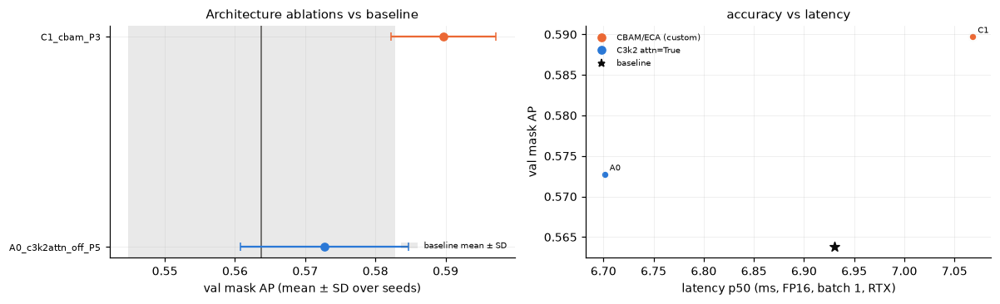

In [23]:
if C3_RUNS:
    rows = [dict(arm="B_baseline", seed=s, **eval_val(rd)) for s, rd in BASELINE_RUNS.items() if s in C3_SEEDS]
    for arm, runs in C3_RUNS.items():
        for s, rd in runs.items():
            rows.append(dict(arm=arm, seed=s, **eval_val(rd)))
    C3ABL = pd.DataFrame(rows)
    b_all = BASE_VAL.mask_AP; b_mean, b_sd = b_all.mean(), b_all.std(ddof=1)
    C3AGG = C3ABL.groupby("arm")[["mask_AP", "mask_AP_gravel", "mask_AP_sand", "mask_APs", "l2_macro_f1"]].agg(["mean", "std"])
    C3AGG[("decision", "beats_baseline")] = (C3AGG[("mask_AP", "mean")] - b_mean) > b_sd
    for arm in ["B_baseline"] + list(C3_ARMS):
        mdl = bm if arm == "B_baseline" else YOLO(str(C3_RUNS[arm][C3_SEEDS[0]] / "weights" / "best.pt")).model
        C3AGG.loc[arm, ("cost", "params")] = sum(p.numel() for p in mdl.parameters())
        C3AGG.loc[arm, ("cost", "GFLOPs")] = get_flops(mdl, 640)
        C3AGG.loc[arm, ("cost", "lat_p50_ms_fp16_bs1")] = model_latency(mdl, 1, True)["p50_ms"]
    save_table(C3ABL, SUB["architecture_ablations"] / "c3k2_attn_runs.csv"); save_table(C3AGG.reset_index(), SUB["architecture_ablations"] / "c3k2_attn_summary.csv")
    print(f"baseline (3 seeds): mean {b_mean:.4f}, SD {b_sd:.4f}")
    display(C3AGG.round(4))
    # เปรียบเทียบทุก arm ของสถาปัตยกรรม (CBAM/ECA และ C3k2 attn) บนแกนเดียวกัน
    ALL = pd.concat([agg.drop(index="B_baseline").assign(family="CBAM/ECA (custom)") if ATT_RUNS else None, C3AGG.drop(index="B_baseline").assign(family="C3k2 attn=True")])
    ALL = ALL[~ALL.index.duplicated()]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    fam_col = {"CBAM/ECA (custom)": "#eb6834", "C3k2 attn=True": "#2a78d6"}
    order = ALL.sort_values(("mask_AP", "mean")).index
    y = np.arange(len(order))
    axes[0].axvspan(b_mean - b_sd, b_mean + b_sd, color="#52514e", alpha=0.12, lw=0, label="baseline mean ± SD")
    axes[0].axvline(b_mean, color="#52514e", lw=1)
    for k, a in enumerate(order):
        r = ALL.loc[a]; c = fam_col.get(r[("family", "")] if ("family", "") in ALL.columns else r["family"], "#52514e")
        axes[0].errorbar(r[("mask_AP", "mean")], k, xerr=r[("mask_AP", "std")], fmt="o", ms=6, color=c, capsize=3, lw=1.5)
    axes[0].set_yticks(y); axes[0].set_yticklabels(order, fontsize=7); axes[0].set_xlabel("val mask AP (mean ± SD over seeds)")
    axes[0].set_title("Architecture ablations vs baseline"); axes[0].legend(frameon=False, fontsize=6.5, loc="lower right")
    for a in ALL.index:
        r = ALL.loc[a]; fam = r[("family", "")] if ("family", "") in ALL.columns else r["family"]
        axes[1].scatter(r[("cost", "lat_p50_ms_fp16_bs1")], r[("mask_AP", "mean")], s=40, color=fam_col.get(fam, "#52514e"), edgecolors="#fcfcfb", linewidths=1.5)
        axes[1].annotate(a.split("_", 1)[0], (r[("cost", "lat_p50_ms_fp16_bs1")], r[("mask_AP", "mean")]), textcoords="offset points", xytext=(4, 3), fontsize=6.5)
    bl = C3AGG.loc["B_baseline"]
    axes[1].scatter(bl[("cost", "lat_p50_ms_fp16_bs1")], b_mean, s=60, marker="*", color="#0b0b0b", label="baseline")
    axes[1].set_xlabel("latency p50 (ms, FP16, batch 1, RTX)"); axes[1].set_ylabel("val mask AP"); axes[1].set_title("accuracy vs latency")
    axes[1].legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=f) for f, c in fam_col.items()] +
                   [Line2D([], [], marker="*", ls="", color="#0b0b0b", label="baseline")], frameon=False, fontsize=6.5)
    fig.tight_layout(); savefig(fig, SUB["architecture_ablations"] / "architecture_all_arms"); plt.show()

attention image: 0022__07451999-bdf8-4862-b869-6db57c35f0c1_mp4-0031_jpg.rf.8a82813520c94a229808c96f13dff77c.jpg [mixed] | queries: {'gravel': (436, 527), 'sand': (487, 384), 'background': (319, 0)}


saved figure: outputs/03_yolo_experiments/feature_maps/B_baseline_s42/psa_attention_maps.png|pdf


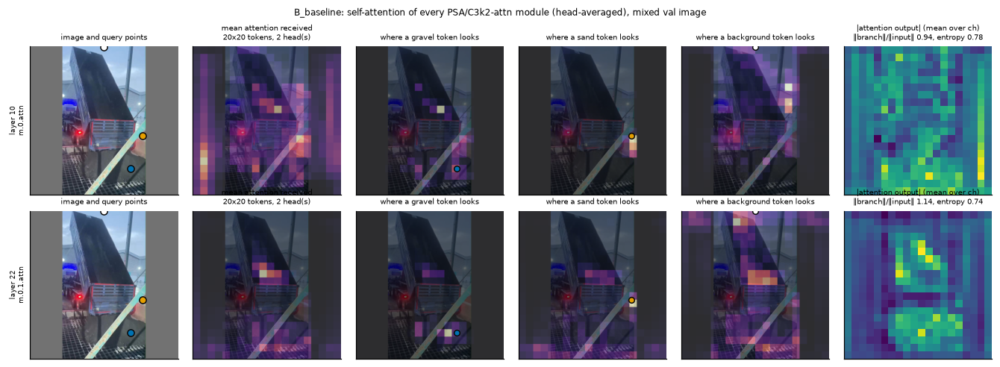

saved figure: outputs/03_yolo_experiments/feature_maps/A0_c3k2attn_off_P5_s42/psa_attention_maps.png|pdf


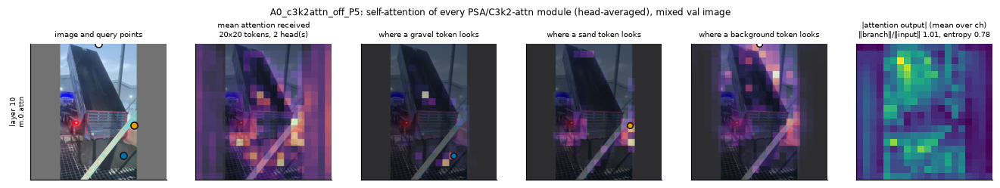

saved table: outputs/03_yolo_experiments/architecture_ablations/psa_attention_stats.csv (3 rows)


,module,layer,tokens,heads,branch_to_input_norm,norm_entropy,arm
0,10_C2PSA.m.0.attn,10,20x20,2,0.937,0.782,B_baseline
1,22_C3k2.m.0.1.attn,22,20x20,2,1.137,0.739,B_baseline
0,10_C2PSA.m.0.attn,10,20x20,2,1.012,0.782,A0_c3k2attn_off_P5


In [24]:
# แผนที่ attention ของทุกโมดูล Attention บนภาพ mixed ของ val (มี query ทั้ง gravel และ sand) สำหรับ baseline และ arm ที่ seed แรก
from matplotlib.lines import Line2D
dev_ = "cuda" if torch.cuda.is_available() else "cpu"
r_att = VAL[VAL.state == "mixed"].iloc[0] if (VAL.state == "mixed").any() else VAL.iloc[0]
img_att = cv2.imread(r_att.path); img_att = TF(img_att) if TF else img_att
x_att, lb_att = letterbox_tensor(img_att)
gt_att = load_gt(GT_VAL); h0, w0 = img_att.shape[:2]
cls_m = {c: np.zeros((h0, w0), np.uint8) for c in CLASS_NAMES}
for a in gt_att.imgToAnns[int(r_att.image_id)]:
    if not a.get("iscrowd", 0):
        cls_m[CLASS_NAMES[a["category_id"] - 1]] |= gt_att.annToMask(a)
LBM, VALID = letterbox_masks(cls_m, (h0, w0)); QPTS = pick_queries(LBM, VALID)
lb_rgb = cv2.cvtColor(lb_att, cv2.COLOR_BGR2RGB)
print(f"attention image: {r_att.silver_name} [{r_att.state}] | queries: {QPTS}")
PSA_ROWS = []
models_ = {"B_baseline": FM_RUN / "weights" / "best.pt"}
models_.update({arm: runs[C3_SEEDS[0]] / "weights" / "best.pt" for arm, runs in C3_RUNS.items()})
for arm, w in models_.items():
    mdl = YOLO(str(w)).model.float().to(dev_).eval()
    rec = capture_psa(mdl, x_att.to(dev_))
    d = SUB["feature_maps"] / f"{arm}_s{C3_SEEDS[0]}"; d.mkdir(parents=True, exist_ok=True)
    t = plot_psa(rec, lb_rgb, QPTS, f"{arm}: self-attention of every PSA/C3k2-attn module (head-averaged), mixed val image", d / "psa_attention_maps")
    PSA_ROWS.append(t.assign(arm=arm)); del mdl, rec; torch.cuda.empty_cache()
PSA_SUM = pd.concat(PSA_ROWS); save_table(PSA_SUM, SUB["architecture_ablations"] / "psa_attention_stats.csv")
display(PSA_SUM.round(3))

### 6.4 ความละเอียดภาพและ hard-group oversampling (สูตรจาก `experiment/results/bench_ws`)  [EXPENSIVE]

**ที่มา** benchmark `bench_ws` ของงานเดิมได้ macro mask AP50 ประมาณ 0.90 แต่ใช้การแบ่งแบบ stripe ที่นำเฟรมจากคลิปเดียวกันไปไว้ทั้งใน train และ test (`experiment/results/gold_ws/frame_assignment.csv`) เมื่อ hold out ทั้งกลุ่ม ค่าลดลงเหลือ 0.325 (`experiment/docs/model_comparison.md`) ผลที่สูงจึงมาจากการแบ่งข้อมูลเป็นหลัก ส่วนนี้จึงนำเฉพาะสูตรการฝึกของ `bench_ws` มาทดสอบภายใต้ S3 group split เดิม โดยไม่ใช้การแบ่งแบบ stripe

| Arm | การเปลี่ยนแปลงจาก baseline | seed |
|---|---|---|
| R1 | imgsz 960 (batch 8 เพื่อให้พอกับหน่วยความจำ; Ultralytics สะสม gradient ให้ได้ nominal batch 64 เท่าเดิม) | 2 |
| R3 | hard-group oversampling: ภาพของกลุ่มยากใน train ถูกนำมาซ้ำรวม 5 เท่า (K = 5 ตาม `bench_ws`) | 2 |
| R2 | YOLO26s-seg ด้วยการตั้งค่าของ n ที่ถูกเลือกในหัวข้อ 7 (ฝึกหลังการเลือก) | 2 |

**การเลือกกลุ่มยาก (กำหนดล่วงหน้า)** ใช้ detection ของ grouped CV รอบแรก (baseline รอบแรก, 3 fold) คำนวณ macro mask AP ของแต่ละกลุ่มเมื่อกลุ่มนั้นอยู่ใน fold ที่ถูก hold out แล้วเลือกเฉพาะกลุ่มที่อยู่ใน train ของ S3 และมีอย่างน้อย 10 ภาพ กลุ่มยากคือกลุ่มที่ macro mask AP อยู่ที่หรือต่ำกว่าควอนไทล์ที่ 25 ไม่ใช้ข้อมูลของ val หรือ test ในการเลือก รายชื่อบันทึกใน `configs/hard_groups.json`

**Limitation** R1 ใช้ batch ต่างจาก baseline และ R3 ทำให้จำนวนภาพต่อ epoch เพิ่มขึ้น ทุก arm ฝึก 60 epoch เต็มโดยไม่ใช้ early stopping จำนวน optimizer step ของ R3 จึงมากกว่า arm อื่น

In [25]:
# กลุ่มยากจาก grouped CV รอบแรก (เฉพาะกลุ่มใน train ของ S3)
HG_PATH = ROOT / "configs" / "hard_groups.json"
K_HARD = 5
if HG_PATH.exists():
    HG = json.loads(HG_PATH.read_text())
else:
    gt_cv = DEV_DIR / "annotations" / "cv_dev_coco.json"
    DEVREC_ = pd.concat([TRAIN, VAL]); train_groups = set(TRAIN.group_merged); rows = []
    for k in range(int(DEV["n_cv_folds"])):
        cands_ = [d for d in SUB["cv"].glob(f"baseline_fold{k}_s{SEED}_*") if (d / "DONE.json").exists() and (d / "eval" / f"dets_fold{k}.json.gz").exists()]
        rd1 = min(cands_, key=lambda d: json.loads((d / "DONE.json").read_text())["finished"])   # run ของรอบแรก (เสร็จก่อน)
        with gzip.open(rd1 / "eval" / f"dets_fold{k}.json.gz", "rt") as f:
            dk = json.load(f)
        vrec = DEVREC_[DEVREC_.cv_fold == k]; res = l1_evaluate(gt_cv, dk, vrec)
        for g, d in vrec.groupby("group_merged"):
            ii = d.image_id.astype(int).tolist()
            rows.append(dict(group=g, fold=k, n=len(ii), in_train=g in train_groups, state=d.state.mode()[0], source_run=str(rd1.relative_to(ROOT)),
                             mask_AP_gravel=ap_from_records(res["segm"]["recs"], ii, 1), mask_AP_sand=ap_from_records(res["segm"]["recs"], ii, 2)))
    GP = pd.DataFrame(rows); GP["macro_mask_AP"] = GP[["mask_AP_gravel", "mask_AP_sand"]].mean(axis=1)
    elig = GP[GP.in_train & (GP.n >= 10)]; thr = float(elig.macro_mask_AP.quantile(0.25))
    HG = dict(groups=elig[elig.macro_mask_AP <= thr].group.tolist(), threshold=thr, K=K_HARD, rule="train groups with n>=10 and macro mask AP <= Q25 in round-1 grouped CV",
              table=GP.round(4).to_dict("records"))
    HG_PATH.write_text(json.dumps(HG, indent=2, default=float))
GP = pd.DataFrame(HG["table"]); save_table(GP, SUB["cv"] / "hard_group_selection.csv")
print("hard groups:", HG["groups"], f"(threshold {HG['threshold']:.3f})")
display(GP.sort_values("macro_mask_AP").round(3))

def stem_group_map():
    m = dict(zip(TRAIN.silver_name.map(lambda n: Path(n).stem), TRAIN.group_merged))
    m.update(dict(zip(VAL.silver_name.map(lambda n: Path(n).stem), VAL.group_merged)))
    return m
STEM_GROUP = stem_group_map()
def oversample(paths, groups, k=K_HARD):
    # ภาพ (รวม variant ของ offline aug) ของกลุ่มยากถูกนำมาซ้ำให้ครบ k เท่า
    hard = [p for p in paths if STEM_GROUP.get(Path(p).stem.split("__aug")[0]) in set(groups)]
    return list(paths) + hard * (k - 1), len(hard)

def hardgroup_data():
    tr = sorted(str(p) for p in (BASE_DATA.parent / "train" / "images").iterdir())
    lst, n_h = oversample(tr, HG["groups"])
    d = SUB["architecture_ablations"] / "hardgroup_data"; d.mkdir(parents=True, exist_ok=True)
    (d / "train.txt").write_text("\n".join(lst) + "\n")
    val_dir = BASE_DATA.parent / "val" / "images" if (BASE_DATA.parent / "val" / "images").exists() else DEV_DIR / "val" / "images"
    (d / "data.yaml").write_text(f"train: {d}/train.txt\nval: {val_dir}\nnc: 2\nnames: ['gravel', 'sand']\n")
    print(f"hard-group data: {len(tr)} images + {n_h * (K_HARD - 1)} repeats = {len(lst)}")
    return d / "data.yaml"
HG_DATA = hardgroup_data()

saved table: outputs/03_yolo_experiments/cv/hard_group_selection.csv (19 rows)
hard groups: ['1991989f-1bf5-4e50-89bb-7301b220ac01', 'bbf45eda-4ffb-4bf1-9b29-a4e91475c8ec'] (threshold 0.382)


,group,fold,n,in_train,state,source_run,mask_AP_gravel,mask_AP_sand,macro_mask_AP
6,68935cd9-3fa0-403f-ba48-4764b89115a0,1,1,True,gravel,outputs/03_yolo_experiments/cv/baseline_fold1_...,0.004,NaN,0.004
12,04802d75-aef4-4463-b9ac-241ba1c9d161,2,1,True,sand,outputs/03_yolo_experiments/cv/baseline_fold2_...,NaN,0.126,0.126
16,bbf45eda-4ffb-4bf1-9b29-a4e91475c8ec,2,36,True,sand,outputs/03_yolo_experiments/cv/baseline_fold2_...,0.001,0.258,0.130
7,9056e676-f14d-410c-9dc7-c5686b3fca04,1,1,True,gravel,outputs/03_yolo_experiments/cv/baseline_fold1_...,0.228,NaN,0.228
0,1991989f-1bf5-4e50-89bb-7301b220ac01,0,65,True,mixed,outputs/03_yolo_experiments/cv/baseline_fold0_...,0.534,0.001,0.267
15,51647d0e-59fc-4bf9-b510-488636e21705,2,1,True,gravel,outputs/03_yolo_experiments/cv/baseline_fold2_...,0.306,NaN,0.306
9,c6f16e4e-55cb-4abc-91ea-0d01ae0d6d28,1,1,True,gravel,outputs/03_yolo_experiments/cv/baseline_fold1_...,0.395,NaN,0.395
13,07451999-bdf8-4862-b869-6db57c35f0c1,2,40,False,gravel,outputs/03_yolo_experiments/cv/baseline_fold2_...,0.428,0.455,0.441
5,6459c886-45a3-4065-82bc-2ed15b2875b0,1,49,False,sand,outputs/03_yolo_experiments/cv/baseline_fold1_...,NaN,0.476,0.476
2,6f40fbbd-891e-434b-a1ec-365668a5ae66,0,47,True,gravel,outputs/03_yolo_experiments/cv/baseline_fold0_...,0.497,NaN,0.497


hard-group data: 3570 images + 2020 repeats = 5590


New https://pypi.org/project/ultralytics/8.4.182 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.180 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3080 Ti, 11902MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=6, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/supawich/Desktop/Aggregate_Project/implement/research/data/preproc_P5_unsharp_A9_1450497fd9/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/supawich/Desktop/Aggregate_Project/implement/research/weights/yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, 

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


...

predicted 131 images -> 3979 detections in 1.9s val


predicted 131 images -> 4326 detections in 2.2s val


saved table: outputs/03_yolo_experiments/architecture_ablations/recipe_arms_runs.csv (6 rows)
saved table: outputs/03_yolo_experiments/architecture_ablations/recipe_arms_summary.csv (3 rows)
baseline (3 seeds): mean 0.5638, SD 0.0190


mask_AP         mask_AP_gravel         mask_AP_sand          \
                mean     std           mean     std         mean     std   
arm                                                                        
B_baseline    0.5633  0.0269         0.6898  0.0300       0.4368  0.0237   
R1_imgsz960   0.5728  0.0091         0.7311  0.0178       0.4145  0.0359   
R3_hardgroup  0.5625  0.0130         0.6970  0.0167       0.4280  0.0427   

             mask_APs         l2_macro_f1          ... epochs_run best_epoch  \
                 mean     std        mean     std  ...        std       mean   
arm                                                ...                         
B_baseline     0.0950  0.0265      0.8028  0.2136  ...        0.0       22.0   
R1_imgsz960    0.0773  0.0347      0.6556  0.2884  ...        0.0       42.0   
R3_hardgroup   0.0945  0.0076      0.6704  0.0311  ...        0.0       37.5   

                      wall_min               decision       cost           \
                  std     mean     std beats_baseline     params   GFLOPs   
arm                                                                         
B_baseline    16.9706  20.3958  0.0106          False  3083302.0  10.4207   
R1_imgsz960    1.4142  39.7592  0.3594          False  3083302.0  23.7922   
R3_hardgroup   3.5355  31.9300  0.0047          False  3083302.0  10.4207   

                                         
              imgsz lat_p50_ms_fp16_bs1  
arm                                      
B_baseline    640.0              6.9094  
R1_imgsz960   960.0              6.9622  
R3_hardgroup  640.0              6.9750  

[3 rows x 21 columns]

saved figure: outputs/03_yolo_experiments/architecture_ablations/round2_arms.png|pdf


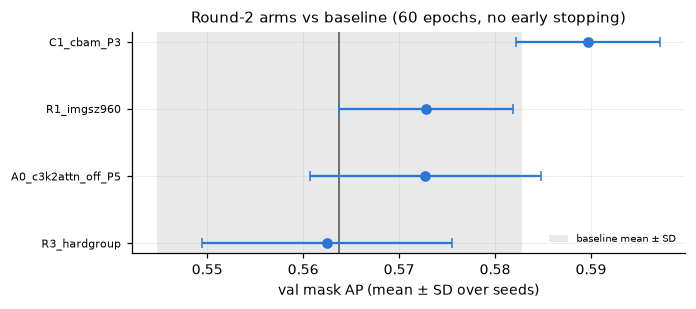

In [26]:
R_ARMS = {"R1_imgsz960": dict(data=BASE_DATA, recipe={**BASE_RECIPE, "imgsz": 960, "batch": 8}),
          "R3_hardgroup": dict(data=HG_DATA, recipe=dict(BASE_RECIPE))}
R_SEEDS = [42, 43]
R_RUNS = defaultdict(dict)
if RUN_TRAINING:
    for arm, a in R_ARMS.items():
        for s in R_SEEDS:
            R_RUNS[arm][s] = train_run(SUB["architecture_ablations"], arm, s, a["data"], a["recipe"])

def stop_info(rd):
    r = read_results_csv(rd)
    return dict(epochs_run=int(r.epoch.max()), best_epoch=int(r.loc[r["metrics/mAP50-95(M)"].idxmax(), "epoch"]),
                wall_min=float((Path(rd) / "wall_time_s.txt").read_text()) / 60 if (Path(rd) / "wall_time_s.txt").exists() else np.nan)

def arm_table(runs_by_arm, include_baseline_seeds):
    rows = [dict(arm="B_baseline", seed=s, **stop_info(rd), **eval_val(rd)) for s, rd in BASELINE_RUNS.items() if s in include_baseline_seeds]
    for arm, runs in runs_by_arm.items():
        for s, rd in runs.items():
            rows.append(dict(arm=arm, seed=s, **stop_info(rd), **eval_val(rd)))
    return pd.DataFrame(rows)

def cost_of(rd):
    mdl = YOLO(str(Path(rd) / "weights" / "best.pt")).model; sz = run_imgsz(rd)
    return dict(params=sum(p.numel() for p in mdl.parameters()), GFLOPs=get_flops(mdl, sz), imgsz=sz,
                lat_p50_ms_fp16_bs1=model_latency(mdl, 1, True, imgsz=sz)["p50_ms"])

if R_RUNS:
    RABL = arm_table(R_RUNS, R_SEEDS)
    b_all = BASE_VAL.mask_AP; b_mean, b_sd = b_all.mean(), b_all.std(ddof=1)
    RAGG = RABL.groupby("arm")[["mask_AP", "mask_AP_gravel", "mask_AP_sand", "mask_APs", "l2_macro_f1", "epochs_run", "best_epoch", "wall_min"]].agg(["mean", "std"])
    RAGG[("decision", "beats_baseline")] = (RAGG[("mask_AP", "mean")] - b_mean) > b_sd
    for arm in ["B_baseline"] + list(R_RUNS):
        rd = BASELINE_RUNS[SEED] if arm == "B_baseline" else R_RUNS[arm][R_SEEDS[0]]
        for k_, v_ in cost_of(rd).items():
            RAGG.loc[arm, ("cost", k_)] = v_
    save_table(RABL, SUB["architecture_ablations"] / "recipe_arms_runs.csv"); save_table(RAGG.reset_index(), SUB["architecture_ablations"] / "recipe_arms_summary.csv")
    print(f"baseline (3 seeds): mean {b_mean:.4f}, SD {b_sd:.4f}")
    display(RAGG.round(4))
    # รวมทุก arm ของรอบที่สองบนกราฟเดียว
    R2ALL = pd.concat([x for x in (agg.drop(index="B_baseline", errors="ignore") if ATT_RUNS else None,
                                   C3AGG.drop(index="B_baseline", errors="ignore") if C3_RUNS else None,
                                   RAGG.drop(index="B_baseline")) if x is not None])
    order = R2ALL.sort_values(("mask_AP", "mean")).index
    fig, ax = plt.subplots(figsize=(6.4, 0.42 * len(order) + 1.2))
    ax.axvspan(b_mean - b_sd, b_mean + b_sd, color="#52514e", alpha=0.12, lw=0, label="baseline mean ± SD")
    ax.axvline(b_mean, color="#52514e", lw=1)
    for k, a in enumerate(order):
        ax.errorbar(R2ALL.loc[a, ("mask_AP", "mean")], k, xerr=R2ALL.loc[a, ("mask_AP", "std")], fmt="o", ms=6, color="#2a78d6", capsize=3, lw=1.5)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=7); ax.set_xlabel("val mask AP (mean ± SD over seeds)")
    ax.set_title("Round-2 arms vs baseline (60 epochs, no early stopping)"); ax.legend(frameon=False, fontsize=6.5, loc="lower right")
    fig.tight_layout(); savefig(fig, SUB["architecture_ablations"] / "round2_arms"); plt.show()

### 6.2 วัตถุขนาดเล็กและ SAHI (ทดสอบยืนยัน)

**Method** ประเมิน baseline บน val ด้วย sliced inference ของ SAHI (slice 320 × 320, overlap 0.2, รวมกับ prediction ของภาพเต็ม) เทียบกับ inference ปกติ โดยใช้ evaluator เดียวกัน

**Rationale** Notebook 01 พบว่า instance ขนาด small ตามเกณฑ์ COCO ส่วนใหญ่เป็นเศษหินบนตะแกรง ซึ่งส่วนมากเป็น ignore region ในชุดประเมิน และงานเดิมพบว่า SAHI ทำให้ผลแย่ลง จึงทดสอบเพียงเพื่อยืนยันกับชุดข้อมูลใหม่

**Reference** Akyon et al. (2022), "Slicing Aided Hyper Inference and Fine-tuning for Small Object Detection", *ICIP* [รอตรวจ]

**Limitation** การรวม prediction ของ slice ใช้ค่าเริ่มต้นของ SAHI (NMS แบบ IOS) ซึ่งอาจไม่เหมาะกับวัตถุแบบ "stuff" ที่ต่อเนื่องเป็นบริเวณใหญ่

In [27]:
RUN_SAHI = RUN_TRAINING
if RUN_SAHI:
    from sahi import AutoDetectionModel
    from sahi.predict import get_sliced_prediction
    sm = AutoDetectionModel.from_pretrained(model_type="ultralytics", model_path=str(FM_RUN / "weights" / "best.pt"),
                                            confidence_threshold=0.001, device="cuda:0", image_size=640)
    def sahi_dets():
        dets = []
        for r in VAL.itertuples():
            img = cv2.imread(r.path); img = TF(img) if TF else img
            pr = get_sliced_prediction(img[..., ::-1].copy(), sm, slice_height=320, slice_width=320, overlap_height_ratio=0.2,
                                       overlap_width_ratio=0.2, perform_standard_pred=True, verbose=0)
            for op in pr.object_prediction_list:
                if op.mask is None:
                    continue
                m = op.mask.bool_mask.astype(np.uint8)
                rle = mask_util.encode(np.asfortranarray(m)); rle["counts"] = rle["counts"].decode()
                x0, y0, x1, y1 = op.bbox.to_xyxy()
                dets.append(dict(image_id=int(r.image_id), category_id=int(op.category.id) + 1, score=float(op.score.value),
                                 segmentation=rle, bbox=[x0, y0, x1 - x0, y1 - y0], area=float(m.sum())))
        return dets
    d_sahi = cached_dets(SUB["architecture_ablations"] / "sahi" / "dets_val.json.gz", sahi_dets)
    r_sahi = l1_evaluate(GT_VAL, d_sahi, VAL)
    SAHI_TAB = pd.DataFrame([dict(method="standard", **{k: v for k, v in eval_val(FM_RUN).items() if k.startswith("mask_")}),
                             dict(method="SAHI 320/0.2", **summarize_l1(r_sahi))])[["method", "mask_AP", "mask_AP50", "mask_APs", "mask_APm", "mask_APl"]]
    save_table(SAHI_TAB, SUB["architecture_ablations"] / "sahi_vs_standard.csv"); display(SAHI_TAB.round(4))

saved table: outputs/03_yolo_experiments/architecture_ablations/sahi_vs_standard.csv (2 rows)


,method,mask_AP,mask_AP50,mask_APs,mask_APm,mask_APl
0,standard,0.5823,0.7934,0.1137,0.4162,0.7388
1,SAHI 320/0.2,0.3816,0.5859,0.0087,0.1474,0.5608


### 6.3 การทดสอบ shortcut: แบบจำลองยังทำนายคลาสได้หรือไม่เมื่อไม่มีวัสดุในภาพ

**Method** สร้างภาพ val ที่ลบบริเวณวัสดุทั้งหมดออก (ทุก instance ใน Silver รวม ignore region ขยายขอบ 5 พิกเซล) ด้วย inpainting แบบ Telea แล้วรัน baseline และวัดคะแนนสถานะ S_c ต่อภาพ ถ้าแบบจำลองยังให้คะแนนของคลาสเดียวกับภาพเดิมสูงในภาพที่ไม่มีวัสดุแล้ว แปลว่าแบบจำลองใช้บริบทของฉาก (รถ ตะแกรง พื้นหลัง) ในการทำนายคลาส

**Rationale** Notebook 01 พบว่าคลาสผูกกับแหล่งที่มาอย่างมาก (Cramér's V = 0.98) จึงต้องทดสอบโดยตรงว่าแบบจำลองเรียนรู้ทางลัดหรือไม่ (Geirhos et al., 2020, *Nature Machine Intelligence* 2: 665–673)

**Limitation** inpainting ทิ้งร่องรอยของบริเวณที่ลบ และอาจสร้างเนื้อผิวที่คล้ายวัสดุจากขอบโดยรอบ ผลจึงเป็นหลักฐานเชิงบ่งชี้ ไม่ใช่การพิสูจน์

saved table: outputs/03_yolo_experiments/evaluation/shortcut_test/shortcut_scores.csv (131 rows)


,S_gravel_orig,S_sand_orig,S_gravel_inpaint,S_sand_inpaint
state,,,,
gravel,0.1480,0.0000,0.0025,0.0000
mixed,0.0923,0.0006,0.0632,0.0000
sand,0.0000,0.1601,0.0000,0.0849


saved figure: outputs/03_yolo_experiments/evaluation/shortcut_test/shortcut_examples.png|pdf


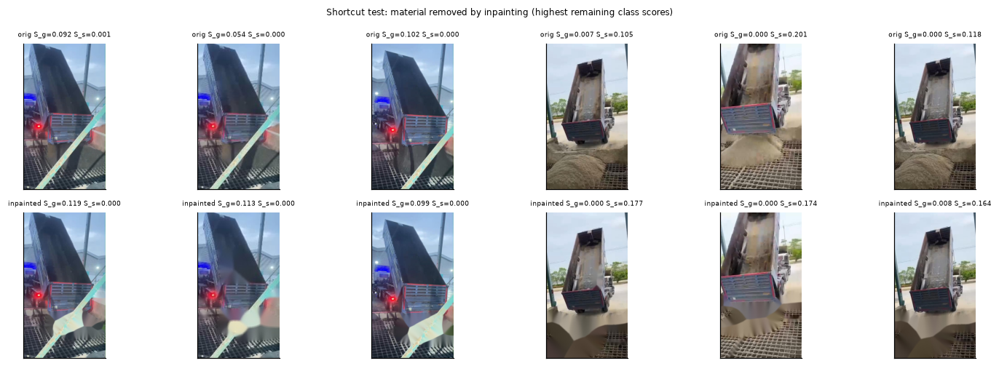

In [28]:
def inpaint_material(r, dilate=5):
    img = cv2.imread(r.path); m = np.zeros(img.shape[:2], np.uint8)
    for line in Path(r.label_path).read_text().splitlines():
        t = line.split()
        p = (np.asarray(t[1:], float).reshape(-1, 2) * [r.width, r.height]).astype(np.int32)
        cv2.fillPoly(m, [p], 255)
    m = cv2.dilate(m, np.ones((2 * dilate + 1, 2 * dilate + 1), np.uint8))
    return cv2.inpaint(img, m, 5, cv2.INPAINT_TELEA), m

SC_DIR = SUB["evaluation"] / "shortcut_test"; SC_DIR.mkdir(parents=True, exist_ok=True)
sc_rows = []
for r in VAL.itertuples():
    out, m = inpaint_material(r)
    p = SC_DIR / "images" / r.silver_name; p.parent.mkdir(exist_ok=True); cv2.imwrite(str(p), out)
    sc_rows.append(dict(image_id=r.image_id, path=str(p), width=r.width, height=r.height, state=r.state, group_merged=r.group_merged,
                        removed_frac=float((m > 0).mean())))
SCV = pd.DataFrame(sc_rows)
d_orig = cached_dets(FM_RUN / "eval" / "dets_val.json.gz", lambda: predict_dets(FM_RUN / "weights" / "best.pt", VAL, transform=TF))
d_inp = cached_dets(SC_DIR / "dets_inpainted.json.gz", lambda: predict_dets(FM_RUN / "weights" / "best.pt", SCV, transform=TF))
s0 = state_scores(d_orig, VAL).add_suffix("_orig").rename(columns={"image_id_orig": "image_id"})
s1 = state_scores(d_inp, SCV).add_suffix("_inpaint").rename(columns={"image_id_inpaint": "image_id"})
SHORT = SCV.merge(s0, on="image_id").merge(s1, on="image_id")
for c in CLASS_NAMES:
    SHORT[f"retained_{c}"] = SHORT[f"S_{c}_inpaint"] / SHORT[f"S_{c}_orig"].replace(0, np.nan)
save_table(SHORT, SC_DIR / "shortcut_scores.csv")
tab = SHORT.groupby("state")[[f"S_{c}_orig" for c in CLASS_NAMES] + [f"S_{c}_inpaint" for c in CLASS_NAMES]].median()
display(tab.round(4))
ex = SHORT.sort_values("S_gravel_inpaint", ascending=False).head(3).image_id.tolist() + SHORT.sort_values("S_sand_inpaint", ascending=False).head(3).image_id.tolist()
fig, axes = plt.subplots(2, len(ex), figsize=(2.3 * len(ex), 4.6))
for c, iid in enumerate(ex):
    ro = VAL[VAL.image_id == iid].iloc[0]; rs = SHORT[SHORT.image_id == iid].iloc[0]
    axes[0, c].imshow(cv2.cvtColor(cv2.imread(ro.path), cv2.COLOR_BGR2RGB)); axes[0, c].set_title(f"orig S_g={rs.S_gravel_orig:.3f} S_s={rs.S_sand_orig:.3f}", fontsize=6)
    axes[1, c].imshow(cv2.cvtColor(cv2.imread(rs.path), cv2.COLOR_BGR2RGB)); axes[1, c].set_title(f"inpainted S_g={rs.S_gravel_inpaint:.3f} S_s={rs.S_sand_inpaint:.3f}", fontsize=6)
    for ax in axes[:, c]:
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Shortcut test: material removed by inpainting (highest remaining class scores)", fontsize=8)
fig.tight_layout(); savefig(fig, SC_DIR / "shortcut_examples"); plt.show()

## 7. การเลือกการตั้งค่าและการยืนยันด้วย grouped CV  [EXPENSIVE]

**เกณฑ์การเลือก (กำหนดล่วงหน้า; ใช้ val เท่านั้น)**

1. ตัวเลือก: baseline, MuSGD และ attention arm ที่ผ่านเกณฑ์ "ดีกว่า baseline เกินส่วนเบี่ยงเบนมาตรฐานของ baseline"
2. ถ้าไม่มีตัวเลือกใดผ่าน ให้ใช้ baseline (สูตรที่ง่ายที่สุด)
3. ถ้ามีหลายตัวเลือกผ่าน ให้เลือกตัวที่ mask AP เฉลี่ยสูงสุด แต่ถ้าต่างจากตัวรองไม่เกินส่วนเบี่ยงเบนมาตรฐานของ baseline ให้เลือกตัวที่ latency (FP16, batch 1) ต่ำกว่า
4. ยืนยันการตั้งค่าที่เลือกเทียบกับ baseline ด้วย grouped CV 3 fold (seed 42) รายงานค่าเฉลี่ยและผลต่างแบบคู่ราย fold โดย train ของแต่ละ fold คือชุดพัฒนา (train ∪ val) ลบ fold นั้น ภาพ offline augmentation มีเฉพาะของภาพที่อยู่ใน train เดิม และจำนวน epoch ปรับให้จำนวน optimizer step ใกล้กับการฝึกบน train เต็ม

**Reference** Roberts et al. (2017) — การยืนยันด้วย block (grouped) CV; Cawley & Talbot (2010), *JMLR* 11: 2079–2107 — การเลือกแบบจำลองบนข้อมูลเดียวกับที่ใช้ประเมินทำให้เกิด selection bias [รอตรวจ]

In [29]:
cands = [dict(name="baseline", kind="base", mask_AP=BASE_VAL.mask_AP.mean(), lat=model_latency(bm, 1, True)["p50_ms"])]
b_mean, b_sd = BASE_VAL.mask_AP.mean(), BASE_VAL.mask_AP.std(ddof=1)
if OPT_RUNS["MuSGD"]:
    m_ = OPT[OPT.optimizer == "MuSGD"].mask_AP.mean()
    if m_ - b_mean > b_sd:
        cands.append(dict(name="MuSGD", kind="opt", mask_AP=m_, lat=cands[0]["lat"]))
if ATT_RUNS:
    for arm in ATT_ARMS:
        m_ = agg.loc[arm, ("mask_AP", "mean")]
        if m_ - b_mean > b_sd:
            cands.append(dict(name=arm, kind="att", mask_AP=m_, lat=agg.loc[arm, ("cost", "lat_p50_ms_fp16_bs1")]))
if C3_RUNS:
    for arm in C3_ARMS:
        m_ = C3AGG.loc[arm, ("mask_AP", "mean")]
        if m_ - b_mean > b_sd:
            cands.append(dict(name=arm, kind="c3attn", mask_AP=m_, lat=C3AGG.loc[arm, ("cost", "lat_p50_ms_fp16_bs1")]))
if R_RUNS:
    for arm in R_ARMS:
        m_ = RAGG.loc[arm, ("mask_AP", "mean")]
        if m_ - b_mean > b_sd:
            cands.append(dict(name=arm, kind="recipe", mask_AP=m_, lat=RAGG.loc[arm, ("cost", "lat_p50_ms_fp16_bs1")]))
C = pd.DataFrame(cands).sort_values("mask_AP", ascending=False).reset_index(drop=True)
if len(C) > 1 and C.mask_AP.iloc[0] - C.mask_AP.iloc[1] <= b_sd:
    SELECTED = C.iloc[:2].sort_values("lat").iloc[0].to_dict()
else:
    SELECTED = C.iloc[0].to_dict()
save_table(C, SUB["evaluation"] / "selection_candidates.csv")
print("selected YOLO26n configuration:", SELECTED)

saved table: outputs/03_yolo_experiments/evaluation/selection_candidates.csv (2 rows)
selected YOLO26n configuration: {'name': 'C1_cbam_P3', 'kind': 'att', 'mask_AP': 0.5897203763828914, 'lat': 7.068160057067871}


### 7.1 YOLO26s-seg ด้วยการตั้งค่าที่ดีที่สุดของ YOLO26n (R2)

**Method** นำการตั้งค่าของ YOLO26n ที่ถูกเลือกข้างต้น (ข้อมูล, preprocessing, augmentation, imgsz, attention และนโยบายการฝึก) มาฝึกกับ YOLO26s-seg (`weights/yolo26s-seg.pt`, pretrained COCO) 2 seed

**เกณฑ์ (กำหนดล่วงหน้าโดยผู้วิจัย)** แบบจำลองสุดท้ายคือ YOLO26s เว้นแต่ค่าเฉลี่ยของ mask AP บน val ต่ำกว่าการตั้งค่าของ n ที่เลือกเกินส่วนเบี่ยงเบนมาตรฐานของ baseline ซึ่งในกรณีนั้นจะใช้ YOLO26n ที่เลือกไว้ ตัวที่ได้จะเข้าสู่ grouped CV และการตรึงในหัวข้อถัดไป

In [30]:
S_WEIGHTS = ROOT / "weights" / "yolo26s-seg.pt"
print("YOLO26s-seg weights sha256:", sha256_file(S_WEIGHTS)[:16])

def config_of(sel):
    """การตั้งค่าครบชุดของ candidate: recipe, trainer, attention spec, data yaml, base weights และการ oversample กลุ่มยาก"""
    name, kind = sel["name"], sel["kind"]
    if kind == "s":
        base = config_of(sel["base"]); base["weights"] = S_WEIGHTS
        if base["att"] and base["att"][0] == "c3attn":
            base["att"] = ("c3attn", {**base["att"][1], "scale": "s"})
        return base
    cfg = dict(recipe=dict(BASE_RECIPE), trainer=None, att=None, data=BASE_DATA, weights=None, hard_groups=False)
    if name == "MuSGD":
        cfg["recipe"] = MUSGD_RECIPE
    elif kind == "att":
        cfg.update(trainer=AttSegTrainer, att=ATT_ARMS[name])
    elif kind == "c3attn":
        cfg.update(trainer=C3k2AttnSegTrainer, att=("c3attn", {**C3_ARMS[name], "scale": "n"}))
    elif kind == "recipe":
        cfg.update(recipe=dict(R_ARMS[name]["recipe"]), data=R_ARMS[name]["data"], hard_groups=name == "R3_hardgroup")
    return cfg

def apply_att(att):
    if att and att[0] == "c3attn":
        C3_SPEC.update(att[1])
    elif att:
        ATT_SPEC.update(kind=att[0], layers=att[1])

S_NAME = f"R2_yolo26s__{SELECTED['name']}"
S_SEL = dict(name=S_NAME, kind="s", base=SELECTED)
S_RUNS = defaultdict(dict)
if RUN_TRAINING:
    cfg = config_of(S_SEL); apply_att(cfg["att"])
    for s in R_SEEDS:
        S_RUNS[S_NAME][s] = train_run(SUB["architecture_ablations"], S_NAME, s, cfg["data"], cfg["recipe"], trainer=cfg["trainer"], weights=cfg["weights"])
if S_RUNS:
    apply_att(config_of(S_SEL)["att"])
    SABL = arm_table(S_RUNS, [])
    sel_runs = {"baseline": BASELINE_RUNS, **{a: dict(r) for a, r in {**ATT_RUNS, **C3_RUNS, **R_RUNS}.items()}}
    apply_att(config_of(SELECTED)["att"])
    NSEL = pd.DataFrame([dict(arm=SELECTED["name"], seed=s, **stop_info(rd), **eval_val(rd)) for s, rd in sel_runs[SELECTED["name"]].items() if s in R_SEEDS])
    SN = pd.concat([NSEL, SABL])
    s_mean, n_mean = SABL.mask_AP.mean(), NSEL.mask_AP.mean()
    FINAL_SEL = S_SEL if s_mean >= n_mean - b_sd else SELECTED
    cs = cost_of(S_RUNS[S_NAME][R_SEEDS[0]]); cn = cost_of(sel_runs[SELECTED["name"]][SEED])
    DEC = pd.DataFrame([dict(model="YOLO26n " + SELECTED["name"], mask_AP_mean=n_mean, mask_AP_sd=NSEL.mask_AP.std(ddof=1), **cn),
                        dict(model="YOLO26s " + SELECTED["name"], mask_AP_mean=s_mean, mask_AP_sd=SABL.mask_AP.std(ddof=1), **cs)])
    DEC["final"] = [FINAL_SEL["kind"] != "s", FINAL_SEL["kind"] == "s"]
    save_table(SN, SUB["architecture_ablations"] / "yolo26s_vs_n_runs.csv"); save_table(DEC, SUB["evaluation"] / "final_model_decision.csv")
    display(SN[["arm", "seed", "epochs_run", "best_epoch", "mask_AP", "mask_AP_gravel", "mask_AP_sand", "mask_APs", "l2_macro_f1"]].round(4)); display(DEC.round(4))
else:
    FINAL_SEL = SELECTED
print("final configuration:", FINAL_SEL["name"])

YOLO26s-seg weights sha256: 3da1d83e31caec96


New https://pypi.org/project/ultralytics/8.4.182 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.180 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3080 Ti, 11902MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=6, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/supawich/Desktop/Aggregate_Project/implement/research/data/preproc_P5_unsharp_A9_1450497fd9/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/supawich/Desktop/Aggregate_Project/implement/research/weights/yolo26s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0,

Overriding model.yaml nc=80 with nc=2


...

predicted 131 images -> 9511 detections in 4.0s val


saved table: outputs/03_yolo_experiments/architecture_ablations/yolo26s_vs_n_runs.csv (4 rows)
saved table: outputs/03_yolo_experiments/evaluation/final_model_decision.csv (2 rows)


,arm,seed,epochs_run,best_epoch,mask_AP,mask_AP_gravel,mask_AP_sand,mask_APs,l2_macro_f1
0,C1_cbam_P3,42,60,27,0.5950,0.7414,0.4486,0.1049,0.7763
1,C1_cbam_P3,43,60,44,0.5844,0.7208,0.4481,0.1180,0.6449
0,R2_yolo26s__C1_cbam_P3,42,60,44,0.5938,0.7476,0.4400,0.0933,0.7245
1,R2_yolo26s__C1_cbam_P3,43,60,14,0.5800,0.6847,0.4753,0.1546,0.7870


,model,mask_AP_mean,mask_AP_sd,params,GFLOPs,imgsz,lat_p50_ms_fp16_bs1,final
0,YOLO26n C1_cbam_P3,0.5897,0.0075,3083912,10.4220,640,7.0348,False
1,YOLO26s C1_cbam_P3,0.5869,0.0098,11437512,37.3277,640,7.5120,True


final configuration: R2_yolo26s__C1_cbam_P3


In [31]:
CV_RUNS = defaultdict(dict)
FINAL_CFG = config_of(FINAL_SEL)
if RUN_TRAINING:
    n_folds = int(DEV["n_cv_folds"])
    # ภาพของ fold ต้องเป็นภาพชุดเดียวกับที่ใช้ฝึกสูตรนั้น: ภาพที่ผ่าน preprocessing และ variant ของ offline aug ใน BASE_DATA
    # (รอบแรกใช้ภาพดิบของ DEV_DIR และไม่มี variant ซึ่งไม่ตรงกับสูตรที่ประเมิน; แก้ในรอบที่สอง)
    PP_ROOT = BASE_DATA.parent
    PP_TRAIN = {f.name: str(f) for f in (PP_ROOT / "train" / "images").iterdir()} if (PP_ROOT / "train" / "images").exists() else {}
    PP_VAL = {f.name: str(f) for f in (PP_ROOT / "val" / "images").iterdir()} if (PP_ROOT / "val" / "images").exists() else {}
    def pp_path(p):
        n = Path(p).name
        return PP_TRAIN.get(n) or PP_VAL.get(n) or str(p)
    for k in range(n_folds):
        tr_raw = (DEV_DIR / "cv" / f"fold{k}_train.txt").read_text().split()
        va_raw = (DEV_DIR / "cv" / f"fold{k}_val.txt").read_text().split()
        tr_stems = {Path(p).stem for p in tr_raw}
        tr_list = [pp_path(p) for p in tr_raw]
        extra = [v for n, v in PP_TRAIN.items() if "__aug" in n and Path(n).stem.split("__aug")[0] in tr_stems]
        fold_dir = SUB["cv"] / f"fold{k}"; fold_dir.mkdir(parents=True, exist_ok=True)
        (fold_dir / "val_pp.txt").write_text("\n".join(pp_path(p) for p in va_raw) + "\n")
        for cfg_name, sel in (("baseline", dict(name="baseline", kind="base")), ("selected", FINAL_SEL)):
            if cfg_name == "selected" and FINAL_SEL["name"] == "baseline":
                continue
            cfg = config_of(sel)
            lst = tr_list + extra
            if cfg["hard_groups"]:
                lst, _ = oversample(lst, HG["groups"])
            (fold_dir / f"train_{cfg_name}.txt").write_text("\n".join(lst) + "\n")
            dy = fold_dir / f"data_{cfg_name}.yaml"
            dy.write_text(f"train: {fold_dir}/train_{cfg_name}.txt\nval: {fold_dir}/val_pp.txt\nnc: 2\nnames: ['gravel', 'sand']\n")
            apply_att(cfg["att"])
            run_name = f"{cfg_name}_fold{k}" if cfg_name == "baseline" else f"{cfg_name}_{sel['name']}_fold{k}"
            CV_RUNS[cfg_name][k] = train_run(SUB["cv"], run_name, SEED, dy, cfg["recipe"], trainer=cfg["trainer"], weights=cfg["weights"])
            print(f"fold {k} {cfg_name}: {len(lst)} train images ({len(extra)} offline variants)")

New https://pypi.org/project/ultralytics/8.4.182 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.180 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3080 Ti, 11902MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=6, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/supawich/Desktop/Aggregate_Project/implement/research/outputs/03_yolo_experiments/cv/fold0/data_baseline.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/supawich/Desktop/Aggregate_Project/implement/research/weights/yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_sc

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 5.7it/s 1.0s

                   all        177        552      0.684      0.589      0.621      0.427      0.725      0.571      0.615      0.443


Speed: 0.5ms preprocess, 1.1ms inference, 0.0ms loss, 0.6ms postprocess per image


Results saved to /home/supawich/Desktop/Aggregate_Project/implement/research/outputs/03_yolo_experiments/cv/selected_R2_yolo26s__C1_cbam_P3_fold2_s42_887addc1


fold 2 selected: 3144 train images (2476 offline variants)


In [32]:
if CV_RUNS:
    gt_all = DEV_DIR / "annotations" / "cv_dev_coco.json"
    if not gt_all.exists():
        a = json.loads((DEV_DIR / "annotations" / "train_coco.json").read_text()); b = json.loads((DEV_DIR / "annotations" / "val_coco.json").read_text())
        off = max(x["id"] for x in a["annotations"]) + 1
        for x in b["annotations"]:
            x["id"] += off
        gt_all.write_text(json.dumps(dict(images=a["images"] + b["images"], annotations=a["annotations"] + b["annotations"], categories=a["categories"])))
    DEVREC = pd.concat([TRAIN, VAL])
    rows = []
    for cfg_name, runs in CV_RUNS.items():
        for k, rd in runs.items():
            vrec = DEVREC[DEVREC.cv_fold == k].copy()
            apply_att(config_of(FINAL_SEL if cfg_name == "selected" else dict(name="baseline", kind="base"))["att"])
            ev = eval_val(rd, label=f"fold{k}", records=vrec, gt=gt_all)
            rows.append(dict(config=cfg_name, fold=k, n_val=len(vrec), **{x: ev[x] for x in ("mask_AP", "mask_AP_gravel", "mask_AP_sand", "box_AP", "l2_macro_f1")}))
    CV = pd.DataFrame(rows); save_table(CV, SUB["cv"] / "cv_results.csv")
    display(CV.groupby("config")[["mask_AP", "mask_AP_gravel", "mask_AP_sand", "l2_macro_f1"]].agg(["mean", "std"]).round(4))
    if "selected" in CV_RUNS:
        p = CV.pivot(index="fold", columns="config", values="mask_AP"); print("paired fold differences (selected − baseline):", (p.selected - p.baseline).round(4).to_dict())

predicted 176 images -> 8684 detections in 4.8s fold0


predicted 176 images -> 6129 detections in 2.9s fold1


predicted 177 images -> 4921 detections in 3.6s fold2


predicted 176 images -> 5514 detections in 3.8s fold0


predicted 176 images -> 7968 detections in 3.5s fold1


predicted 177 images -> 4214 detections in 3.5s fold2


saved table: outputs/03_yolo_experiments/cv/cv_results.csv (6 rows)


mask_AP         mask_AP_gravel         mask_AP_sand          \
            mean     std           mean     std         mean     std   
config                                                                 
baseline  0.4493  0.0849         0.5812  0.0652       0.3173  0.1207   
selected  0.4145  0.0959         0.5900  0.0340       0.2389  0.1766   

         l2_macro_f1          
                mean     std  
config                        
baseline      0.7727  0.0981  
selected      0.4068  0.1404

paired fold differences (selected − baseline): {0: -0.0587, 1: -0.0406, 2: -0.0051}


## 8. ตรึงการตั้งค่า (ด่านตรวจ G4) และประเมินบน test ครั้งเดียว

**Method** บันทึก `configs/frozen_inference.yaml` ซึ่งระบุ checkpoint (path และ SHA-256), imgsz, preprocessing, threshold ราย class สำหรับ operating point (F1 สูงสุดบน val ที่ IoU 0.5) และ threshold ของสถานะ (L2) ที่เลือกบน val จากนั้นประเมินบน test ทั้ง L1 (strict และ ignore) และ L2 พร้อม cluster bootstrap 1,000 รอบ ผลรายกลุ่ม ขนาด และตัวอย่าง TP/FP/FN

checkpoint ที่ตรึงคือ seed 42 ของการตั้งค่าที่เลือก (ฝึกบน train ทั้งหมด) ผลของ seed อื่นบน test ไม่รายงานเพื่อเลือก แต่รายงานเป็นช่วงของความแปรปรวนหลังจากตรึงแล้ว

cell ประเมิน test เขียนไฟล์ `outputs/03_yolo_experiments/evaluation/TEST_OPENED.json` เมื่อรันครั้งแรก และจะไม่รันซ้ำถ้าไฟล์นี้มีอยู่ เว้นแต่ลบไฟล์ด้วยตนเองพร้อมบันทึกเหตุผล

**Reference** Boundary IoU: Cheng et al. (2021), *CVPR* (dilation ratio 0.02 ของเส้นทแยงมุมของภาพ) [รอตรวจ]; cluster bootstrap ตามหัวข้อ 9.4 ของแผนการวิจัย

**รอบที่สอง (post-hoc):** ชุด test ถูกเปิดไปแล้วในรอบแรก (ผลอยู่ใน `outputs/_archive_round1/03_evaluation/`) การประเมินในรอบนี้จึงเป็นการวิเคราะห์หลังเปิดผล ไม่ใช่การยืนยันแบบ confirmatory และต้องรายงานแยกจากรอบแรก

In [33]:
SEL_RUNS = {"baseline": BASELINE_RUNS, "MuSGD": OPT_RUNS.get("MuSGD", {})}
SEL_RUNS.update({a: dict(r) for a, r in {**ATT_RUNS, **C3_RUNS, **R_RUNS, **S_RUNS}.items()})
frozen_rd = Path(SEL_RUNS[FINAL_SEL["name"]][SEED]); FCFG = config_of(FINAL_SEL); apply_att(FCFG["att"])
FROZEN_IMGSZ = run_imgsz(frozen_rd)
dets_v = cached_dets(frozen_rd / "eval" / "dets_val.json.gz", lambda: predict_dets(frozen_rd / "weights" / "best.pt", VAL, imgsz=FROZEN_IMGSZ, transform=TF))
res_v = l1_evaluate(GT_VAL, dets_v, VAL)
ops = {c: operating_point(res_v["segm"]["recs"], VAL.image_id.tolist(), i + 1).sort_values("F1").iloc[-1].to_dict() for i, c in enumerate(CLASS_NAMES)}
th_state = fit_state_thresholds(state_scores(dets_v, VAL), VAL)
att_ = FCFG["att"]
FROZEN = dict(selected=FINAL_SEL["name"], round=2, model_size="s" if FINAL_SEL["kind"] == "s" else "n",
              weights=str((frozen_rd / "weights" / "best.pt").relative_to(ROOT)),
              weights_sha256=sha256_file(frozen_rd / "weights" / "best.pt"), imgsz=FROZEN_IMGSZ, preprocessing=PP_NAME,
              preprocessing_params=dict(TARGET_L=TARGET_L),
              attention=(None if not att_ else dict(kind="c3k2_attn", **att_[1]) if att_[0] == "c3attn" else dict(kind=att_[0], layers=list(att_[1]))),
              training_policy=SEL.get("training_policy"), hard_groups=HG["groups"] if FCFG["hard_groups"] else None,
              conf_thresholds={c: ops[c]["conf"] for c in CLASS_NAMES},
              val_operating_point=ops, state_min_conf=STATE_MIN_CONF, state_thresholds=th_state, max_det=100, retina_masks=True,
              dev_hash=DEV["dev_hash"], silver_hash=DEV["silver_hash"], ultralytics=ultralytics.__version__,
              frozen=time.strftime("%Y-%m-%dT%H:%M:%S%z"))
FROZEN = json.loads(json.dumps(FROZEN, default=float))      # แปลงชนิด numpy เป็นชนิดของ Python ก่อนเขียน yaml
FROZEN_PATH = ROOT / "configs" / "frozen_inference.yaml"
if FROZEN_PATH.exists():
    old = _yaml.safe_load(FROZEN_PATH.read_text())
    assert old["weights_sha256"] == FROZEN["weights_sha256"], "frozen config exists with different weights — do not overwrite after test was opened"
    FROZEN = old
else:
    FROZEN_PATH.write_text(_yaml.safe_dump(FROZEN, sort_keys=False))
print(FROZEN_PATH.read_text())

selected: R2_yolo26s__C1_cbam_P3
round: 2
model_size: s
weights: outputs/03_yolo_experiments/architecture_ablations/R2_yolo26s__C1_cbam_P3_s42_c8de8872/weights/best.pt
weights_sha256: accdf2e4453c5c3cbeaa3b39d76898c34a491d6a109b82c6d4cc33458234e09a
imgsz: 640
preprocessing: P5_unsharp
preprocessing_params:
  TARGET_L: 70.56271362304688
attention:
  kind: cbam
  layers:
  - 16
training_policy:
  max_epochs: 60
  patience: 60
  optimizer: AdamW
hard_groups: null
conf_thresholds:
  gravel: 0.37
  sand: 0.28
val_operating_point:
  gravel:
    conf: 0.37
    TP: 194.0
    FP: 8.0
    FN: 31.0
    precision: 0.9603960396039604
    recall: 0.8622222222222222
    F1: 0.9086651053864169
  sand:
    conf: 0.28
    TP: 108.0
    FP: 47.0
    FN: 86.0
    precision: 0.6967741935483871
    recall: 0.5567010309278351
    F1: 0.6189111747851003
state_min_conf: 0.05
state_thresholds:
  gravel: 0.014245966302328453
  sand: 0.001276440419015716
max_det: 100
retina_masks: true
dev_hash: 19659e679798
silv

In [34]:
def boundary_iou(gt_mask, dt_mask, dilation_ratio=0.02):
    h, w = gt_mask.shape; d = max(1, int(round(dilation_ratio * np.hypot(h, w))))
    k = np.ones((3, 3), np.uint8)
    def band(m):
        er = cv2.erode(m.astype(np.uint8), k, iterations=d)
        return m.astype(bool) & ~er.astype(bool)
    g, p = band(gt_mask), band(dt_mask)
    u = (g | p).sum()
    return float((g & p).sum() / u) if u else float("nan")

TEST_FLAG = SUB["evaluation"] / "TEST_OPENED.json"
if RUN_TEST_EVAL:
    assert FROZEN_PATH.exists(), "G4: frozen config missing"
    if TEST_FLAG.exists():
        print("test already evaluated:", TEST_FLAG.read_text()); raise SystemExit("refusing to re-open the test set")
    TEST = split_images("test"); guard_not_test(TEST.path, allow=True)
    GT_TEST = DEV_DIR / "annotations" / "test_coco.json"
    W = ROOT / FROZEN["weights"]; assert sha256_file(W) == FROZEN["weights_sha256"]
    TEST_FLAG.write_text(json.dumps(dict(opened=time.strftime("%Y-%m-%dT%H:%M:%S%z"), weights_sha256=FROZEN["weights_sha256"]), indent=2))
    dets_t = cached_dets(SUB["evaluation"] / "dets_test.json.gz", lambda: predict_dets(W, TEST, imgsz=FROZEN["imgsz"], transform=TF, desc="TEST"))
    RT = l1_evaluate(GT_TEST, dets_t, TEST); RT_strict = l1_evaluate(GT_TEST, dets_t, TEST, strict=True)
    ids = TEST.image_id.tolist()
    op_rows = []
    for i, c in enumerate(CLASS_NAMES):
        o = operating_point(RT["segm"]["recs"], ids, i + 1, thresholds=[FROZEN["conf_thresholds"][c]]).iloc[0].to_dict()
        op_rows.append(dict(cls=c, **o))
    OPS_T = pd.DataFrame(op_rows)
    sc_t = state_scores(dets_t, TEST); L2T, L2T_df = l2_evaluate(sc_t, TEST, FROZEN["state_thresholds"])
    def l2_boot(ii):
        # ภาพที่ถูกสุ่มซ้ำต้องนับซ้ำ จึงสร้าง id ใหม่ต่อแถวก่อนคำนวณ
        sub = sc_t.set_index("image_id").loc[ii].reset_index(drop=True); rec = TEST.set_index("image_id").loc[ii].reset_index(drop=True)
        sub["image_id"] = np.arange(len(sub)); rec["image_id"] = np.arange(len(rec))
        return l2_evaluate(sub, rec, FROZEN["state_thresholds"])[0]["macro_f1"]
    BOOT = dict(mask_AP=bootstrap_mask_ap(RT, TEST, 1000), l2_macro_f1=cluster_bootstrap(TEST, l2_boot, 1000))
    per_group = []
    for g, d in TEST.groupby("group_merged"):
        gi = d.image_id.tolist()
        per_group.append(dict(group=g[:8], n=len(gi), state=d.state.mode()[0], L_mean=None,
                              mask_AP_gravel=ap_from_records(RT["segm"]["recs"], gi, 1), mask_AP_sand=ap_from_records(RT["segm"]["recs"], gi, 2)))
    PG = pd.DataFrame(per_group)
    TEST_SUMMARY = dict(protocol_ignore=summarize_l1(RT), protocol_strict=summarize_l1(RT_strict), operating_point=OPS_T.to_dict("records"),
                        l2={k: v for k, v in L2T.items()}, bootstrap=BOOT)
    (SUB["evaluation"] / "test_summary.json").write_text(json.dumps(TEST_SUMMARY, indent=2, default=float))
    save_table(PG, SUB["evaluation"] / "test_per_group.csv"); save_table(OPS_T, SUB["evaluation"] / "test_operating_point.csv")
    save_table(L2T_df, SUB["evaluation"] / "test_state_predictions.csv")
    print(json.dumps(TEST_SUMMARY, indent=2, default=float)[:3000]); display(PG)

predicted 244 images -> 6535 detections in 4.6s TEST


/home/supawich/Desktop/Aggregate_Project/implement/research/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)


/home/supawich/Desktop/Aggregate_Project/implement/research/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)


/home/supawich/Desktop/Aggregate_Project/implement/research/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)
/home/supawich/Desktop/Aggregate_Project/implement/research/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)
/home/supawich/Desktop/Aggregate_Project/implement/research/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the 

/home/supawich/Desktop/Aggregate_Project/implement/research/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)


...

/home/supawich/Desktop/Aggregate_Project/implement/research/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)


/home/supawich/Desktop/Aggregate_Project/implement/research/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)


saved table: outputs/03_yolo_experiments/evaluation/test_per_group.csv (7 rows)
saved table: outputs/03_yolo_experiments/evaluation/test_operating_point.csv (2 rows)
saved table: outputs/03_yolo_experiments/evaluation/test_state_predictions.csv (244 rows)
{
  "protocol_ignore": {
    "mask_AP": 0.4663650886735615,
    "mask_AP50": 0.7353996474913493,
    "mask_AP75": 0.4450521849153519,
    "mask_APs": 0.16193092507625287,
    "mask_APm": 0.4656004912698874,
    "mask_APl": 0.5599507970116044,
    "mask_AP_gravel": 0.5667891894037456,
    "mask_AP_sand": 0.3659409879433775,
    "box_AP": 0.48261743301652776,
    "box_AP50": 0.6855765898373356,
    "box_AP75": 0.5470500112485918,
    "box_APs": 0.21662367475994218,
    "box_APm": 0.5038936602282611,
    "box_APl": 0.5252801099482857,
    "box_AP_gravel": 0.5820475131236099,
    "box_AP_sand": 0.3831873529094456
  },
  "protocol_strict": {
    "mask_AP": 0.4546166230284024,
    "mask_AP50": 0.7224636963832508,
    "mask_AP75": 0.43177979

/home/supawich/Desktop/Aggregate_Project/implement/research/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)


,group,n,state,L_mean,mask_AP_gravel,mask_AP_sand
0,0a48349e,81,sand,None,NaN,0.373385
1,0f964fdb,111,gravel,None,0.496923,NaN
2,26af764e,1,gravel,None,0.722772,NaN
3,4a7f29af,48,mixed,None,0.898025,0.405217
4,5d14519a,1,sand,None,NaN,0.312871
5,7a600bac,1,gravel,None,0.799010,NaN
6,7b6b3d3f,1,gravel,None,0.628713,NaN


saved table: outputs/03_yolo_experiments/evaluation/test_tp_fp_fn.csv (851 rows)
saved table: outputs/03_yolo_experiments/evaluation/test_boundary_iou.csv (494 rows)


kind,FN,FP,TP
cls,,,
gravel,123,37,321
sand,115,82,173


,boundary_iou,mask_iou
cls,,
gravel,0.7090,0.8363
sand,0.6973,0.8098


saved figure: outputs/03_yolo_experiments/evaluation/test_failure_cases.png|pdf


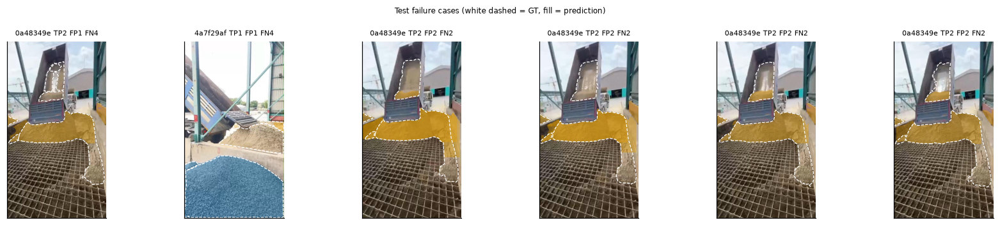

In [35]:
# ตัวอย่าง TP / FP / FN และ Boundary IoU บน test (ใช้ threshold ที่ตรึงไว้)
if RUN_TEST_EVAL:
    gt_t = load_gt(GT_TEST)
    rows, biou = [], []
    for r in TEST.itertuples():
        anns = [a for a in gt_t.imgToAnns[r.image_id] if not a["iscrowd"]]
        gms = [(a["category_id"], gt_t.annToMask(a)) for a in anns]
        dts = [d for d in dets_t if d["image_id"] == r.image_id and d["score"] >= FROZEN["conf_thresholds"][CLASS_NAMES[d["category_id"] - 1]]]
        dms = [(d["category_id"], mask_util.decode(d["segmentation"]), d["score"]) for d in dts]
        used = set()
        for gc, gm in gms:
            best, bj = 0, -1
            for j, (dc, dm, s) in enumerate(dms):
                if j in used or dc != gc:
                    continue
                iou = (gm & dm).sum() / max((gm | dm).sum(), 1)
                if iou > best:
                    best, bj = iou, j
            if best >= 0.5:
                used.add(bj); rows.append(dict(image_id=r.image_id, kind="TP", cls=CLASS_NAMES[gc - 1], iou=best))
                biou.append(dict(cls=CLASS_NAMES[gc - 1], boundary_iou=boundary_iou(gm, dms[bj][1]), mask_iou=best))
            else:
                rows.append(dict(image_id=r.image_id, kind="FN", cls=CLASS_NAMES[gc - 1], iou=best))
        for j, (dc, dm, s) in enumerate(dms):
            if j not in used:
                rows.append(dict(image_id=r.image_id, kind="FP", cls=CLASS_NAMES[dc - 1], iou=np.nan))
    ERR = pd.DataFrame(rows); BI = pd.DataFrame(biou)
    save_table(ERR, SUB["evaluation"] / "test_tp_fp_fn.csv"); save_table(BI, SUB["evaluation"] / "test_boundary_iou.csv")
    display(pd.crosstab(ERR.cls, ERR.kind)); display(BI.groupby("cls")[["boundary_iou", "mask_iou"]].mean().round(4))
    # ภาพตัวอย่างที่มี FN และ FP มากที่สุด
    worst = ERR[ERR.kind != "TP"].groupby("image_id").size().nlargest(6).index
    fig, axes = plt.subplots(1, len(worst), figsize=(2.6 * len(worst), 3.2))
    for ax, iid in zip(np.atleast_1d(axes), worst):
        r = TEST[TEST.image_id == iid].iloc[0]; img = cv2.imread(r.path)
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for a in gt_t.imgToAnns[iid]:
            seg = a["segmentation"][0]; xy = np.asarray(seg).reshape(-1, 2)
            ax.add_patch(MplPolygon(xy, fill=False, edgecolor="white", ls="--", lw=0.8))
        for d in dets_t:
            if d["image_id"] == iid and d["score"] >= FROZEN["conf_thresholds"][CLASS_NAMES[d["category_id"] - 1]]:
                m = mask_util.decode(d["segmentation"]); col = matplotlib.colors.to_rgb(CLASS_COLORS[CLASS_NAMES[d["category_id"] - 1]])
                rgba = np.zeros((*m.shape, 4)); rgba[m > 0] = [*col, 0.4]; ax.imshow(rgba)
        e = ERR[ERR.image_id == iid].kind.value_counts().to_dict()
        ax.set_title(f"{r.group_merged[:8]} TP{e.get('TP',0)} FP{e.get('FP',0)} FN{e.get('FN',0)}", fontsize=7)
    fig.suptitle("Test failure cases (white dashed = GT, fill = prediction)", fontsize=8)
    fig.tight_layout(); savefig(fig, SUB["evaluation"] / "test_failure_cases"); plt.show()

## 9. ตารางเปรียบเทียบสุดท้าย

ตารางรวมผลของ baseline, optimizer และ attention บน val (ค่าเฉลี่ย ± SD ราย seed) พร้อมต้นทุน และบรรทัดของผลบน test ของการตั้งค่าที่ตรึงแล้ว ผลบน test ไม่ถูกใช้ในการเลือกใด ๆ

In [36]:
rows = [dict(config="baseline (AdamW)", val_mask_AP=BASE_VAL.mask_AP.mean(), val_mask_AP_sd=BASE_VAL.mask_AP.std(ddof=1),
             params=sum(p.numel() for p in bm.parameters()), GFLOPs=get_flops(bm, 640), lat_fp16_bs1_ms=model_latency(bm, 1, True)["p50_ms"])]
if OPT_RUNS["MuSGD"]:
    o = OPT[OPT.optimizer == "MuSGD"]; rows.append(dict(config="MuSGD", val_mask_AP=o.mask_AP.mean(), val_mask_AP_sd=o.mask_AP.std(ddof=1),
                                                        params=rows[0]["params"], GFLOPs=rows[0]["GFLOPs"], lat_fp16_bs1_ms=rows[0]["lat_fp16_bs1_ms"]))
if ATT_RUNS:
    for arm in ATT_ARMS:
        rows.append(dict(config=arm, val_mask_AP=agg.loc[arm, ("mask_AP", "mean")], val_mask_AP_sd=agg.loc[arm, ("mask_AP", "std")],
                         params=agg.loc[arm, ("cost", "params")], GFLOPs=agg.loc[arm, ("cost", "GFLOPs")], lat_fp16_bs1_ms=agg.loc[arm, ("cost", "lat_p50_ms_fp16_bs1")]))
for tab_, fam in ((C3AGG if C3_RUNS else None, "c3attn"), (RAGG if R_RUNS else None, "recipe")):
    if tab_ is not None:
        for arm in tab_.index.drop("B_baseline", errors="ignore"):
            rows.append(dict(config=arm, val_mask_AP=tab_.loc[arm, ("mask_AP", "mean")], val_mask_AP_sd=tab_.loc[arm, ("mask_AP", "std")],
                             params=tab_.loc[arm, ("cost", "params")], GFLOPs=tab_.loc[arm, ("cost", "GFLOPs")], lat_fp16_bs1_ms=tab_.loc[arm, ("cost", "lat_p50_ms_fp16_bs1")]))
if S_RUNS:
    rows.append(dict(config=S_NAME, val_mask_AP=SABL.mask_AP.mean(), val_mask_AP_sd=SABL.mask_AP.std(ddof=1), params=cs["params"], GFLOPs=cs["GFLOPs"], lat_fp16_bs1_ms=cs["lat_p50_ms_fp16_bs1"]))
FINAL = pd.DataFrame(rows)
if (SUB["evaluation"] / "test_summary.json").exists():
    ts = json.loads((SUB["evaluation"] / "test_summary.json").read_text())
    FINAL["test_mask_AP (frozen only)"] = [ts["protocol_ignore"]["mask_AP"] if c.startswith(FINAL_SEL["name"]) or (FINAL_SEL["name"] == "baseline" and c.startswith("baseline")) else np.nan for c in FINAL.config]
save_table(FINAL, TAB / "final_comparison.csv")
FINAL.round(4)

saved table: outputs/03_yolo_experiments/tables/final_comparison.csv (6 rows)


,config,val_mask_AP,val_mask_AP_sd,params,GFLOPs,lat_fp16_bs1_ms,test_mask_AP (frozen only)
0,baseline (AdamW),0.5638,0.0190,3083302.0,10.4207,7.1581,NaN
1,C1_cbam_P3,0.5897,0.0075,3083912.0,10.4220,7.0682,NaN
2,A0_c3k2attn_off_P5,0.5727,0.0120,2999078.0,10.2910,6.7011,NaN
3,R1_imgsz960,0.5728,0.0091,3083302.0,23.7922,6.9622,NaN
4,R3_hardgroup,0.5625,0.0130,3083302.0,10.4207,6.9750,NaN
5,R2_yolo26s__C1_cbam_P3,0.5869,0.0098,11437512.0,37.3277,7.5120,0.4664


## 10. Quantization และการวัดประสิทธิภาพบนอุปกรณ์ปลายทาง  [RUN_EXPORT]

**Method** ใช้แบบจำลองที่ตรึงแล้ว (FP32 PyTorch) เป็นค่าอ้างอิง แล้ว export และวัดผล

| อุปกรณ์ | Format / precision | Calibration |
|---|---|---|
| RTX 3080 Ti | PyTorch FP16, ONNX FP32 (ONNX Runtime CUDA), TensorRT FP16, TensorRT INT8 | INT8: ภาพจาก train 400 ภาพแบบสุ่มแบ่งชั้นตามกลุ่ม |
| Raspberry Pi 5 (CPU ARM) | ONNX FP32, NCNN FP16, OpenVINO FP32, OpenVINO INT8 (NNCF post-training quantization) | INT8: ชุด calibration เดียวกัน |

สิ่งที่รายงาน: mask/box AP และ L2 macro-F1 บน val และ test (หลังตรึงแล้วเท่านั้น), ขนาดไฟล์, latency p50/p95 และ throughput, หน่วยความจำ, และความต่างเชิงตัวเลขเทียบกับ FP32 (mask IoU ของ prediction ที่จับคู่กัน และผลต่างของ confidence)

ความแม่นยำของ format สำหรับ RPi5 วัดในเครื่องนี้ด้วย runtime เดียวกันบน CPU x86 ส่วน latency บน RPi5 วัดบนบอร์ดจริงโดยผู้วิจัย ด้วย cell ในหัวข้อ 10.2 แล้วนำไฟล์ผลมาใส่ที่ `outputs/03_yolo_experiments/quantization/rpi5_results.json`

**Reference** Jacob et al. (2018), *CVPR* — integer-only inference [รอตรวจ]; Nagel et al. (2021), arXiv:2106.08295 — แนวทาง post-training quantization [รอตรวจ]; Ultralytics export, TensorRT, OpenVINO และ NCNN integration documentation [รอตรวจ]

**Limitation** INT8 ของ TensorRT และ OpenVINO ใช้วิธี calibration ต่างกัน ความต่างของผลจึงสะท้อนทั้ง precision และ implementation; ความแม่นยำบน ARM อาจต่างจาก x86 เล็กน้อย

In [37]:
# ติดตั้ง runtime ที่จำเป็นสำหรับ export (ครั้งเดียว)  [RUN_EXPORT]
def ensure(pkgs):
    missing = [p for p in pkgs if pkg_version(p.split("==")[0]) is None]
    if missing:
        uv = shutil.which("uv") or str(Path.home() / ".local" / "bin" / "uv")
        subprocess.check_call([uv, "pip", "install", "--python", sys.executable, *missing])
    print({p: pkg_version(p.split("==")[0]) for p in pkgs})

if RUN_EXPORT:
    ensure(["tensorrt-cu13", "nncf", "ncnn", "onnxruntime-gpu"])

In [38]:
QDIR = SUB["quantization"]
if RUN_EXPORT:
    W = ROOT / FROZEN["weights"]
    calib = TRAIN.groupby("group_merged", group_keys=False).apply(lambda d: d.sample(min(len(d), max(1, round(400 * len(d) / len(TRAIN)))), random_state=SEED))
    (QDIR / "calib.txt").write_text("\n".join(calib.path) + "\n")
    (QDIR / "calib.yaml").write_text(f"train: {QDIR}/calib.txt\nval: {QDIR}/calib.txt\nnc: 2\nnames: ['gravel', 'sand']\n")
    EXPORTS = {}
    specs = {"onnx_fp32": dict(format="onnx", simplify=True), "engine_fp16": dict(format="engine", quantize=16),
             "engine_int8": dict(format="engine", quantize=8, data=str(QDIR / "calib.yaml")),
             "openvino_fp32": dict(format="openvino"), "openvino_int8": dict(format="openvino", quantize=8, data=str(QDIR / "calib.yaml")),
             "ncnn_fp16": dict(format="ncnn", quantize=16)}
    for name, kw in specs.items():
        dst = QDIR / name
        if (dst / "EXPORTED.json").exists():
            EXPORTS[name] = json.loads((dst / "EXPORTED.json").read_text())["path"]; continue
        dst.mkdir(parents=True, exist_ok=True)
        tmp = dst / "best.pt"; shutil.copy2(W, tmp)
        try:
            p = YOLO(str(tmp)).export(imgsz=FROZEN["imgsz"], device=0 if name.startswith("engine") or name == "onnx_fp32" else "cpu", **kw)
            EXPORTS[name] = str(p)
            (dst / "EXPORTED.json").write_text(json.dumps(dict(path=str(p), args=kw, time=time.strftime("%Y-%m-%dT%H:%M:%S%z")), indent=2))
        except Exception as e:
            (dst / "EXPORT_FAILED.txt").write_text(repr(e)); print(f"[export failed] {name}: {e!r}")
    print(json.dumps(EXPORTS, indent=2))

In [39]:
def path_size_mb(p):
    p = Path(p)
    return (sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) if p.is_dir() else p.stat().st_size) / 2**20

def bench_exported(path, device, n=100, warm=20, half=False):
    m = YOLO(str(path), task="segment")
    imgs = [cv2.imread(p) for p in VAL.path.head(20)]
    for i in range(warm):
        m.predict(imgs[i % len(imgs)], imgsz=FROZEN["imgsz"], device=device, quantize=16 if half else None, verbose=False)
    sp = [m.predict(imgs[i % len(imgs)], imgsz=FROZEN["imgsz"], device=device, quantize=16 if half else None, verbose=False)[0].speed for i in range(n)]
    s = pd.DataFrame(sp)
    return dict(inf_p50_ms=float(s.inference.median()), inf_p95_ms=float(s.inference.quantile(0.95)),
                total_p50_ms=float((s.preprocess + s.inference + s.postprocess).median()), fps_inference=float(1000 / s.inference.median()))

def match_discrepancy(d_ref, d_q, thr=0.25):
    by = defaultdict(list)
    for d in d_q:
        if d["score"] >= thr:
            by[d["image_id"]].append(d)
    ious, dconf = [], []
    for d in d_ref:
        if d["score"] < thr:
            continue
        best, bd = 0, None
        for q in by[d["image_id"]]:
            if q["category_id"] != d["category_id"]:
                continue
            iou = mask_util.iou([q["segmentation"]], [d["segmentation"]], [0])[0][0]
            if iou > best:
                best, bd = iou, q
        ious.append(best); dconf.append(abs(bd["score"] - d["score"]) if bd else np.nan)
    return dict(matched_mask_iou_median=float(np.median(ious)) if ious else np.nan, frac_ref_dets_unmatched=float(np.mean(np.asarray(ious) < 0.5)) if ious else np.nan,
                conf_abs_diff_median=float(np.nanmedian(dconf)) if dconf else np.nan)

if RUN_EXPORT:
    W = ROOT / FROZEN["weights"]
    variants = {"pytorch_fp32": (W, 0, False), "pytorch_fp16": (W, 0, True)}
    variants.update({k: (v, 0 if k.startswith("engine") or k == "onnx_fp32" else "cpu", False) for k, v in EXPORTS.items()})
    TEST_OK = TEST_FLAG.exists()
    TEST = split_images("test") if TEST_OK else None
    ref_val = None; rows = []
    for name, (p, device, half) in variants.items():
        recs = dict(val=VAL)
        if TEST_OK:
            recs["test"] = TEST
        row = dict(variant=name, device=str(device), size_MB=path_size_mb(p))
        for split, R in recs.items():
            gt = DEV_DIR / "annotations" / f"{split}_coco.json"
            def pred(R=R, p=p, device=device, half=half):
                m = YOLO(str(p), task="segment"); dets = []
                for r in R.itertuples():
                    img = cv2.imread(r.path); img = TF(img) if TF else img
                    out = m.predict(img, imgsz=FROZEN["imgsz"], conf=0.001, max_det=100, retina_masks=True, device=device, quantize=16 if half else None, verbose=False)[0]
                    if out.masks is None:
                        continue
                    for mk, b, c, s in zip(out.masks.data.cpu().numpy().astype(np.uint8), out.boxes.xyxy.cpu().numpy(),
                                           out.boxes.cls.cpu().numpy().astype(int), out.boxes.conf.cpu().numpy()):
                        if mk.shape != (r.height, r.width):
                            mk = cv2.resize(mk, (r.width, r.height), interpolation=cv2.INTER_NEAREST)
                        rle = mask_util.encode(np.asfortranarray(mk)); rle["counts"] = rle["counts"].decode()
                        dets.append(dict(image_id=int(r.image_id), category_id=int(c) + 1, score=float(s), segmentation=rle,
                                         bbox=[float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])], area=float(mk.sum())))
                return dets
            d = cached_dets(QDIR / name / f"dets_{split}.json.gz", pred)
            res = l1_evaluate(gt, d, R); s = summarize_l1(res)
            l2, _ = l2_evaluate(state_scores(d, R), R, FROZEN["state_thresholds"])
            row.update({f"{split}_mask_AP": s["mask_AP"], f"{split}_box_AP": s["box_AP"], f"{split}_l2_macro_f1": l2["macro_f1"]})
            if split == "val":
                if name == "pytorch_fp32":
                    ref_val = d
                else:
                    row.update({f"vs_fp32_{k}": v for k, v in match_discrepancy(ref_val, d).items()})
        try:
            row.update(bench_exported(p, device, half=half))
        except Exception as e:
            row["bench_error"] = repr(e)
        rows.append(row)
    QUANT = pd.DataFrame(rows); save_table(QUANT, QDIR / "quantization_results.csv"); display(QUANT.round(4))

### 10.2 Benchmark บน Raspberry Pi 5 (รันบนบอร์ด)

cell ต่อไปนี้ออกแบบให้รันใน notebook นี้บน Raspberry Pi 5 โดยตั้ง `RUN_ON_RPI5 = True` ต้องคัดลอกโฟลเดอร์ `outputs/03_yolo_experiments/quantization/` (ที่มีไฟล์ export) และภาพ val 20 ภาพแรกไปยังบอร์ดตาม path เดียวกันภายใต้ `ROOT` โปรโตคอลเหมือนกับการวัดบนเครื่องนี้: warm-up 20 รอบ วัด 100 รอบ batch 1 imgsz 640 บันทึกอุณหภูมิ CPU ก่อนและหลังการวัด (throttling มีผลต่อ latency ของ RPi5) แล้วบันทึกผลเป็น `rpi5_results.json`

In [40]:
RUN_ON_RPI5 = False
if RUN_ON_RPI5:
    def cpu_temp():
        try:
            return float(Path("/sys/class/thermal/thermal_zone0/temp").read_text()) / 1000
        except Exception:
            return None
    res = dict(device=platform.platform(), python=sys.version.split()[0], ultralytics=pkg_version("ultralytics"),
               start_temp_c=cpu_temp(), time=time.strftime("%Y-%m-%dT%H:%M:%S%z"), variants={})
    for name in ["onnx_fp32", "ncnn_fp16", "openvino_fp32", "openvino_int8"]:
        ex = SUB["quantization"] / name / "EXPORTED.json"
        if ex.exists():
            p = Path(json.loads(ex.read_text())["path"]); p = SUB["quantization"] / name / p.name if not p.exists() else p
            try:
                res["variants"][name] = dict(**bench_exported(p, "cpu"), temp_after_c=cpu_temp())
            except Exception as e:
                res["variants"][name] = dict(error=repr(e))
    (SUB["quantization"] / "rpi5_results.json").write_text(json.dumps(res, indent=2)); print(json.dumps(res, indent=2))

rp = SUB["quantization"] / "rpi5_results.json"
if rp.exists():
    R5 = pd.DataFrame(json.loads(rp.read_text())["variants"]).T
    save_table(R5.reset_index().rename(columns={"index": "variant"}), SUB["quantization"] / "rpi5_latency.csv"); display(R5)
else:
    print("RPi5 results not yet available:", rp.relative_to(ROOT))

RPi5 results not yet available: outputs/03_yolo_experiments/quantization/rpi5_results.json


## 11. สรุปผลของ Notebook 03

ส่วนนี้เขียนหลังรันครบ โดยอ้างตัวเลขจากไฟล์ผลเท่านั้น

| คำถาม | หลักฐาน |
|---|---|
| RQ4 AdamW เทียบกับ MuSGD | `optimizer_comparison/optimizer_summary.csv`, learning curves |
| RQ5 feature map | `feature_maps/baseline_s42/` และ `overview_all_layers.png` |
| RQ6 ต้นทุนรายชั้นและความสัมพันธ์ FLOPs–latency | `layer_benchmarks/per_layer_cost.csv`, ค่า Spearman ρ |
| RQ7 quantization | `quantization/quantization_results.csv`, `rpi5_latency.csv` |
| RQ8 CBAM/ECA | `architecture_ablations/attention_summary.csv` |
| RQ10 การตั้งค่าที่เลือก | `configs/frozen_inference.yaml`, `cv/cv_results.csv`, `tables/final_comparison.csv` |
| RQ11 L1 เทียบกับ L2 | `evaluation/test_summary.json` |
| Shortcut test | `evaluation/shortcut_test/shortcut_scores.csv` |